Essa versão so usa os tipos como condicional

In [5]:
import os
import re
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from io import BytesIO
from pathlib import Path
from tqdm.auto import tqdm
from collections import Counter

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# Dados

In [6]:
SEED = 42

BASE_DIR = Path("poke_sprite")

RAW_DIR = BASE_DIR / "raw"
PROCESSED_DIR = BASE_DIR / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

METADATA_PATH = BASE_DIR / "metadata.csv"
STATS_PATH = BASE_DIR / "sprite_stats.csv"
SPLIT_PATH = BASE_DIR / "dataset_split.csv"

IMAGE_SIZE = 64
MARGIN = 4

print("Diretório:", BASE_DIR.resolve())
print("Tamanho final:", IMAGE_SIZE, "x", IMAGE_SIZE)

Diretório: C:\Mestrado\VAE\poke_sprite
Tamanho final: 64 x 64


In [6]:
session = requests.Session()

retry_strategy = Retry(
    total=5,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

adapter = HTTPAdapter(
    max_retries=retry_strategy
)

session.mount("https://", adapter)
session.mount("http://", adapter)


def get_json(url):

    response = session.get(
        url,
        timeout=30
    )

    response.raise_for_status()

    return response.json()

In [9]:
if METADATA_PATH.exists():

    print("Metadados encontrados. Carregando arquivo local...")

    df_pokemon = pd.read_csv(METADATA_PATH)

    df_pokemon["types"] = df_pokemon["types"].apply(
        lambda value: value.split("|") if isinstance(value, str) else []
    )

else:

    print("Metadados não encontrados. Consultando PokeAPI...")

    species_list_url = (
        "https://pokeapi.co/api/v2/pokemon-species/"
        "?limit=2000&offset=0"
    )

    species_response = get_json(species_list_url)

    species_results = species_response["results"]

    print("Espécies encontradas:", len(species_results))

    pokemon_data = []
    
    GENERATION_MAP = {
        "generation-i": 1,
        "generation-ii": 2,
        "generation-iii": 3,
        "generation-iv": 4,
        "generation-v": 5,
        "generation-vi": 6,
        "generation-vii": 7,
        "generation-viii": 8,
        "generation-ix": 9
    }

    for species_item in tqdm(species_results):

        # Informações completas da espécie
        species = get_json(species_item["url"])

        # Identificar a variedade padrão
        default_variety = next(
            (
                variety
                for variety in species["varieties"]
                if variety["is_default"]
            ),
            None
        )

        if default_variety is None:
            continue

        # Informações do Pokémon padrão
        pokemon = get_json(
            default_variety["pokemon"]["url"]
        )

        # Tipos ordenados
        types = sorted(
            pokemon["types"],
            key=lambda item: item["slot"]
        )

        type_names = [
            item["type"]["name"]
            for item in types
        ]

        # Geração da espécie
        # Geração da espécie
        generation = species["generation"]["name"]

        generation_number = GENERATION_MAP.get(generation)

        if generation_number is None:
            raise ValueError(
                f"Geração não mapeada: {generation}"
            )

        pokemon_data.append({

            "id": species["id"],

            "name": species["name"],

            "pokemon_name": pokemon["name"],

            "generation": generation,

            "generation_number": generation_number,

            "types": "|".join(type_names),

            "num_types": len(type_names),

            "sprite_url": pokemon["sprites"]["front_default"]
        })

        # Pequena pausa para evitar sobrecarregar a API
        time.sleep(0.05)

    df_pokemon = pd.DataFrame(pokemon_data)

    df_pokemon.to_csv(
        METADATA_PATH,
        index=False
    )

    # Padronizar a coluna types
    df_pokemon["types"] = df_pokemon["types"].apply(
        lambda value: value.split("|") if isinstance(value, str) else []
    )

print("\nTotal de espécies:", len(df_pokemon))

display(df_pokemon.head(10))

Metadados não encontrados. Consultando PokeAPI...
Espécies encontradas: 1025


  0%|          | 0/1025 [00:00<?, ?it/s]


Total de espécies: 1025


,id,name,pokemon_name,generation,generation_number,types,num_types,sprite_url
0,1,bulbasaur,bulbasaur,generation-i,1,"[grass, poison]",2,https://raw.githubusercontent.com/PokeAPI/spri...
1,2,ivysaur,ivysaur,generation-i,1,"[grass, poison]",2,https://raw.githubusercontent.com/PokeAPI/spri...
2,3,venusaur,venusaur,generation-i,1,"[grass, poison]",2,https://raw.githubusercontent.com/PokeAPI/spri...
3,4,charmander,charmander,generation-i,1,[fire],1,https://raw.githubusercontent.com/PokeAPI/spri...
4,5,charmeleon,charmeleon,generation-i,1,[fire],1,https://raw.githubusercontent.com/PokeAPI/spri...
5,6,charizard,charizard,generation-i,1,"[fire, flying]",2,https://raw.githubusercontent.com/PokeAPI/spri...
6,7,squirtle,squirtle,generation-i,1,[water],1,https://raw.githubusercontent.com/PokeAPI/spri...
7,8,wartortle,wartortle,generation-i,1,[water],1,https://raw.githubusercontent.com/PokeAPI/spri...
8,9,blastoise,blastoise,generation-i,1,[water],1,https://raw.githubusercontent.com/PokeAPI/spri...
9,10,caterpie,caterpie,generation-i,1,[bug],1,https://raw.githubusercontent.com/PokeAPI/spri...


In [10]:
generation_counts = (
    df_pokemon.groupby("generation_number")
    .size()
    .sort_index()
)

print("Quantidade de espécies por geração:")
display(generation_counts.to_frame("quantidade"))

print(
    "\nGeração mais recente:",
    df_pokemon["generation_number"].max()
)

Quantidade de espécies por geração:


,quantidade
generation_number,
1,151
2,100
3,135
4,107
5,156
6,72
7,88
8,96
9,120



Geração mais recente: 9


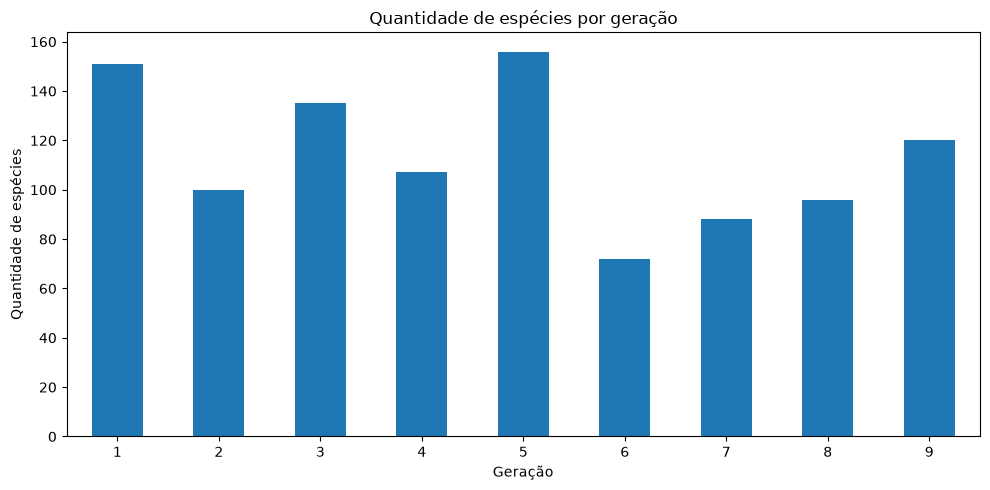

In [11]:
plt.figure(figsize=(10, 5))

generation_counts.plot(
    kind="bar"
)

plt.title("Quantidade de espécies por geração")
plt.xlabel("Geração")
plt.ylabel("Quantidade de espécies")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
print("Pokémon com um tipo:")
print((df_pokemon["num_types"] == 1).sum())

print("\nPokémon com dois tipos:")
print((df_pokemon["num_types"] == 2).sum())

print("\nRegistros com quantidade inesperada de tipos:")
print(
    (~df_pokemon["num_types"].isin([1, 2])).sum()
)

Pokémon com um tipo:
499

Pokémon com dois tipos:
526

Registros com quantidade inesperada de tipos:
0


,quantidade
water,154
normal,131
grass,127
flying,109
psychic,102
bug,92
poison,83
fire,81
ground,75
rock,74


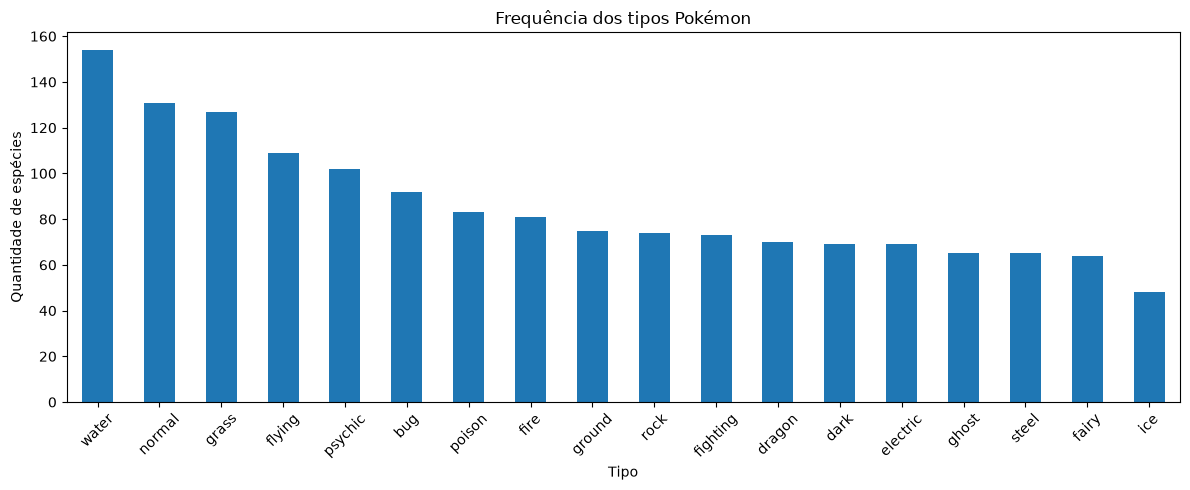

In [13]:
type_counter = Counter(
    pokemon_type
    for types in df_pokemon["types"]
    for pokemon_type in types
)

type_frequency = pd.Series(
    type_counter
).sort_values(ascending=False)

display(type_frequency.to_frame("quantidade"))

plt.figure(figsize=(12, 5))

type_frequency.plot(kind="bar")

plt.title("Frequência dos tipos Pokémon")
plt.xlabel("Tipo")
plt.ylabel("Quantidade de espécies")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [42]:
# Remover referências antigas antes de reconstruir os caminhos
columns_to_rebuild = [
    "raw_path",
    "download_status",
    "processed_path",
    "processing_status"
]

df_pokemon = df_pokemon.drop(
    columns=[
        col for col in columns_to_rebuild
        if col in df_pokemon.columns
    ]
)

print("Referências locais serão reconstruídas.")

Referências locais serão reconstruídas.


In [14]:
download_status = []

for _, row in tqdm(
    df_pokemon.iterrows(),
    total=len(df_pokemon)
):

    pokemon_id = int(row["id"])

    pokemon_name = row["pokemon_name"]

    sprite_url = row["sprite_url"]

    filename = f"{pokemon_id:04d}_{pokemon_name}.png"

    filepath = RAW_DIR / filename

    if pd.isna(sprite_url):

        download_status.append({
            "id": pokemon_id,
            "raw_path": None,
            "download_status": "missing_url"
        })

        continue

    # Não baixar novamente se o arquivo já existir
    if filepath.exists():

        try:
            with Image.open(filepath) as image:
                image.verify()

            download_status.append({
                "id": pokemon_id,
                "raw_path": str(filepath),
                "download_status": "already_exists"
            })

            continue

        except Exception:
            # Arquivo inválido: será baixado novamente
            filepath.unlink()

    try:

        response = session.get(
            sprite_url,
            timeout=30
        )

        response.raise_for_status()

        image = Image.open(
            BytesIO(response.content)
        ).convert("RGBA")

        image.save(filepath, format="PNG")

        download_status.append({
            "id": pokemon_id,
            "raw_path": str(filepath),
            "download_status": "downloaded"
        })

    except Exception as error:

        download_status.append({
            "id": pokemon_id,
            "raw_path": None,
            "download_status": f"error: {error}"
        })

df_downloads = pd.DataFrame(download_status)

df_pokemon = df_pokemon.merge(
    df_downloads,
    on="id",
    how="left"
)

print("Resumo dos downloads:")
display(
    df_pokemon["download_status"].value_counts().to_frame("quantidade")
)

print(
    "\nSprites existentes:",
    sum(1 for _ in RAW_DIR.glob("*.png"))
)

df_pokemon.to_csv(
    METADATA_PATH,
    index=False
)

  0%|          | 0/1025 [00:00<?, ?it/s]

Resumo dos downloads:


,quantidade
download_status,
downloaded,1025



Sprites existentes: 1025


In [15]:
sprite_stats = []

for _, row in tqdm(df_pokemon.iterrows(), total=len(df_pokemon)):

    if pd.isna(row["raw_path"]):
        continue

    filepath = Path(row["raw_path"])

    if not filepath.exists():
        continue

    image = Image.open(filepath).convert("RGBA")

    rgba = np.array(image)

    alpha = rgba[:, :, 3]

    sprite_stats.append({

        "id": row["id"],

        "name": row["pokemon_name"],

        "generation": row["generation_number"],

        "width": image.width,

        "height": image.height,

        "alpha_min": alpha.min(),

        "alpha_max": alpha.max(),

        "transparent_pixels": np.sum(alpha == 0),

        "opaque_pixels": np.sum(alpha == 255),

        "partial_alpha_pixels": np.sum(
            (alpha > 0) & (alpha < 255)
        )
    })

df_sprite_stats = pd.DataFrame(sprite_stats)

df_sprite_stats.to_csv(
    STATS_PATH,
    index=False
)

print("Estatísticas dos sprites:")
display(df_sprite_stats.head(15))

print("\nDimensões mais frequentes:")
display(
    df_sprite_stats.groupby(
        ["width", "height"]
    ).size().sort_values(ascending=False).head(10)
)

print(
    "\nSprites com transparência:",
    (df_sprite_stats["transparent_pixels"] > 0).sum()
)

print(
    "\nSprites com alfa parcial:",
    (df_sprite_stats["partial_alpha_pixels"] > 0).sum()
)

  0%|          | 0/1025 [00:00<?, ?it/s]

Estatísticas dos sprites:


,id,name,generation,width,height,alpha_min,alpha_max,transparent_pixels,opaque_pixels,partial_alpha_pixels
0,1,bulbasaur,1,96,96,0,255,8370,846,0
1,2,ivysaur,1,96,96,0,255,7538,1678,0
2,3,venusaur,1,96,96,0,255,5276,3940,0
3,4,charmander,1,96,96,0,255,8396,820,0
4,5,charmeleon,1,96,96,0,255,7874,1342,0
5,6,charizard,1,96,96,0,255,5628,3588,0
6,7,squirtle,1,96,96,0,255,8358,858,0
7,8,wartortle,1,96,96,0,255,7365,1851,0
8,9,blastoise,1,96,96,0,255,6611,2605,0
9,10,caterpie,1,96,96,0,255,8565,651,0



Dimensões mais frequentes:


width  height
96     96        1025
dtype: int64


Sprites com transparência: 1025

Sprites com alfa parcial: 1


In [16]:
def inspect_sprite(pokemon_id):

    pokemon = df_pokemon[
        df_pokemon["id"] == pokemon_id
    ].iloc[0]

    image = Image.open(
        pokemon["raw_path"]
    ).convert("RGBA")

    rgba = np.array(image)

    alpha = rgba[:, :, 3]

    # Fundo branco
    white_background = Image.new(
        "RGBA",
        image.size,
        (255, 255, 255, 255)
    )

    composite = Image.alpha_composite(
        white_background,
        image
    ).convert("RGB")

    fig, axes = plt.subplots(
        1, 3,
        figsize=(12, 4)
    )

    axes[0].imshow(image)
    axes[0].set_title("Sprite original RGBA")

    axes[1].imshow(
        alpha,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1].set_title("Máscara alfa")

    axes[2].imshow(composite)
    axes[2].set_title("Composição sobre branco")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"{pokemon['pokemon_name'].capitalize()} | "
        f"Geração {pokemon['generation_number']} | "
        f"Tipos: {pokemon['types']}"
    )

    plt.tight_layout()
    plt.show()

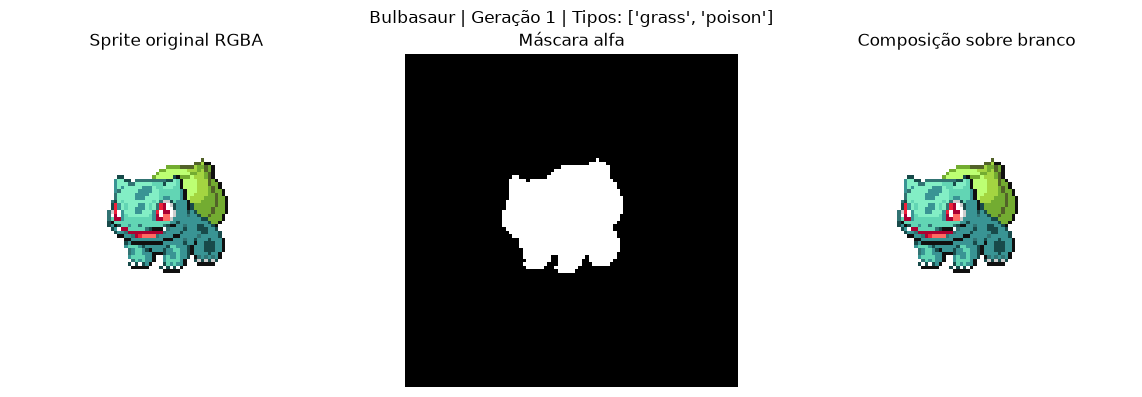

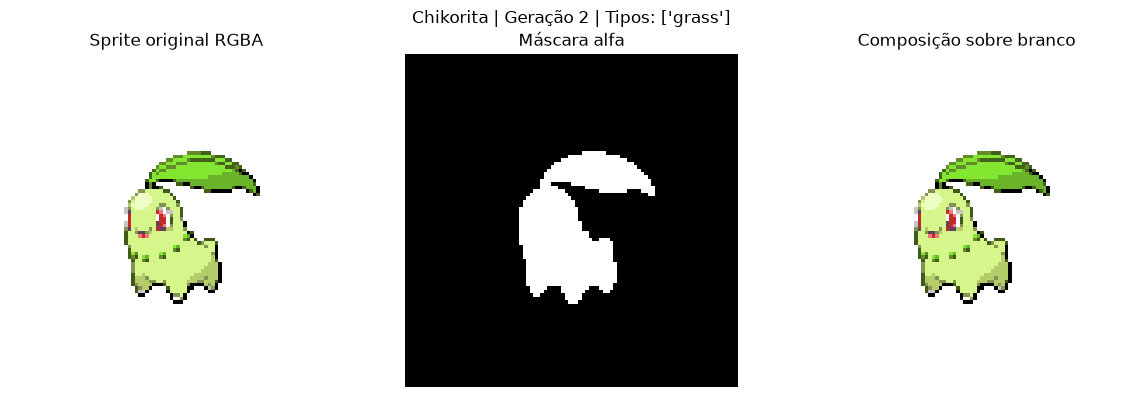

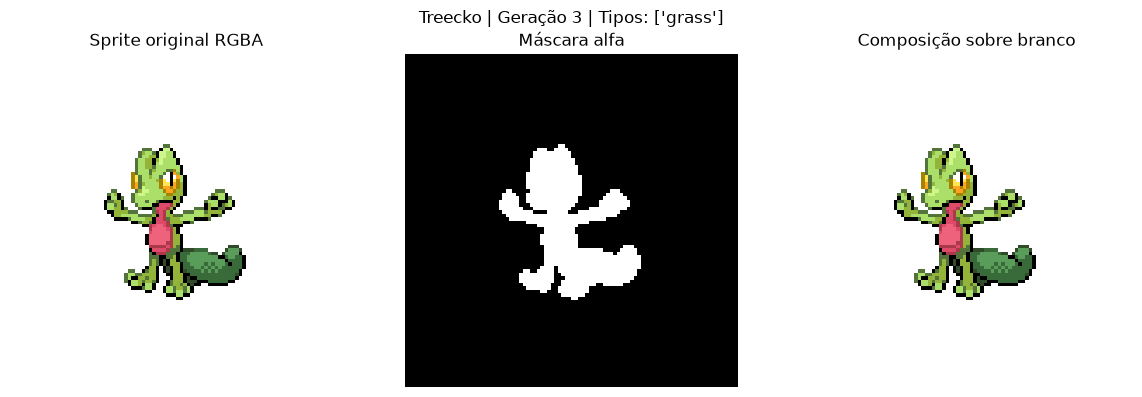

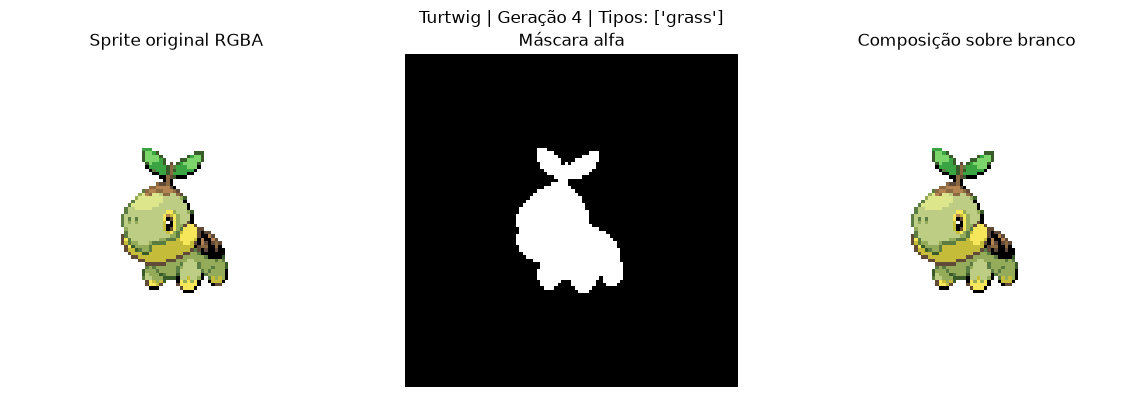

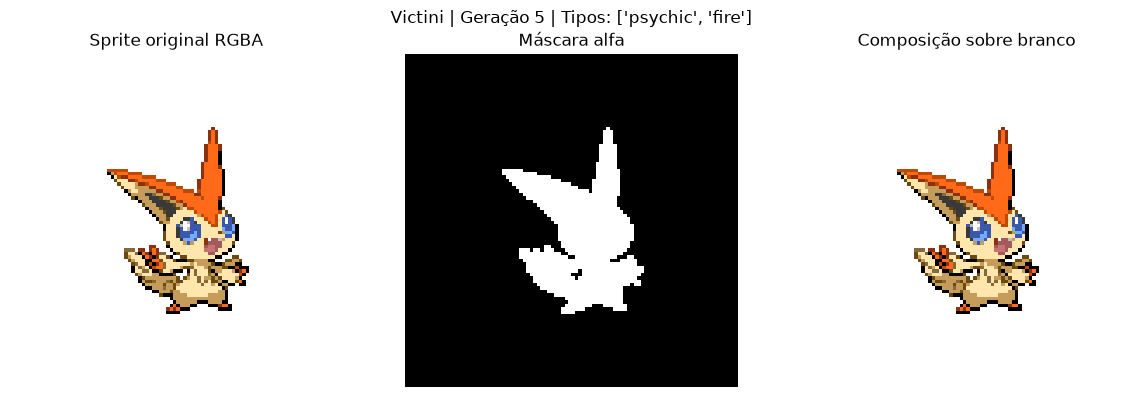

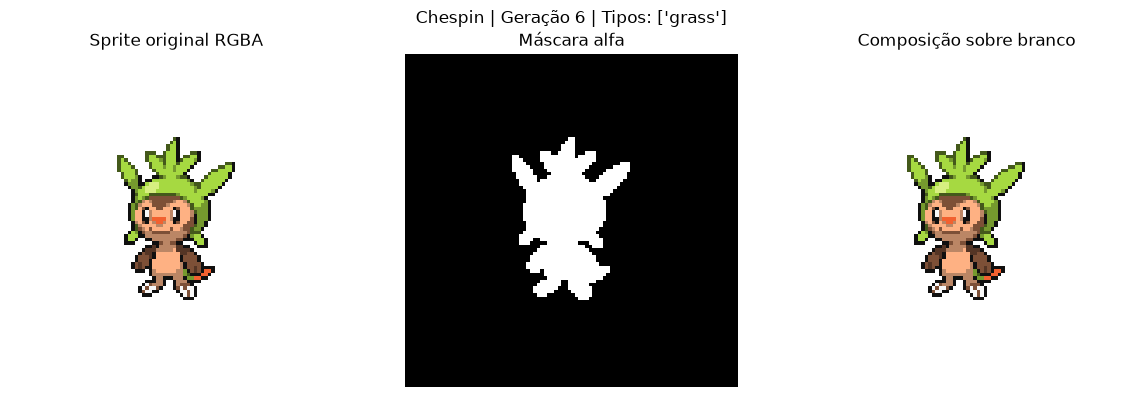

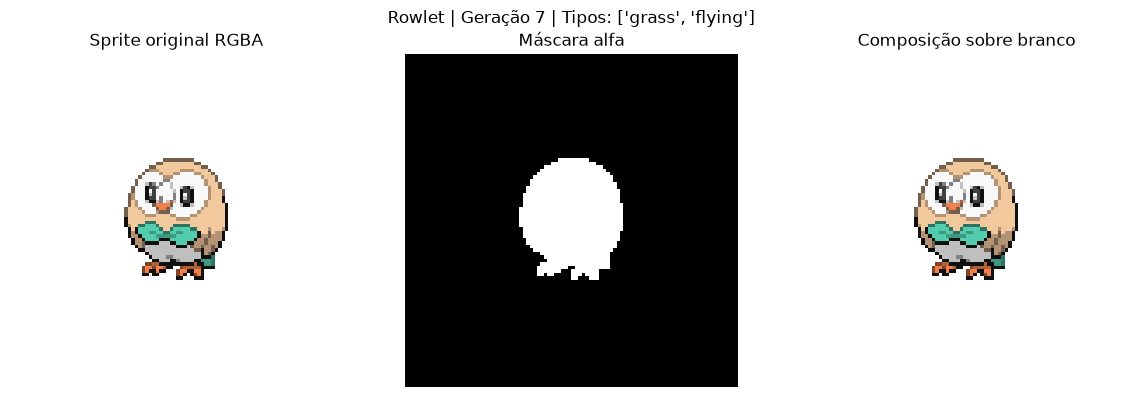

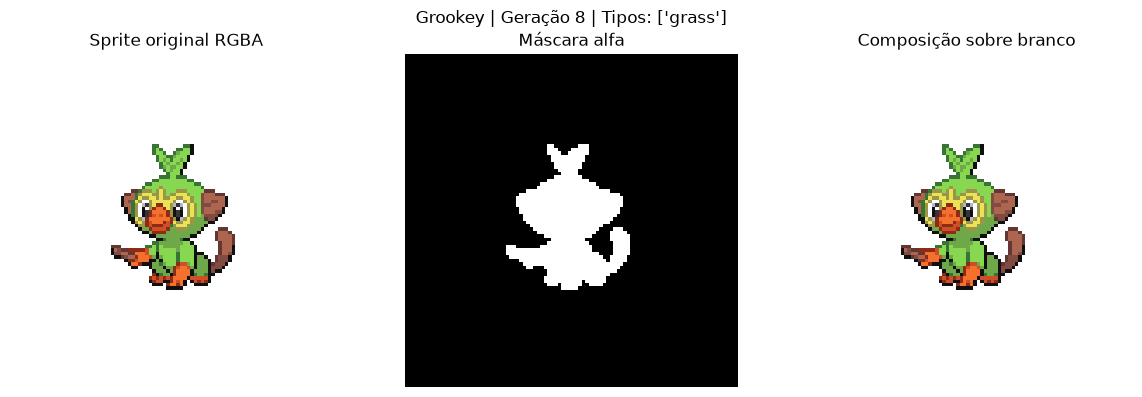

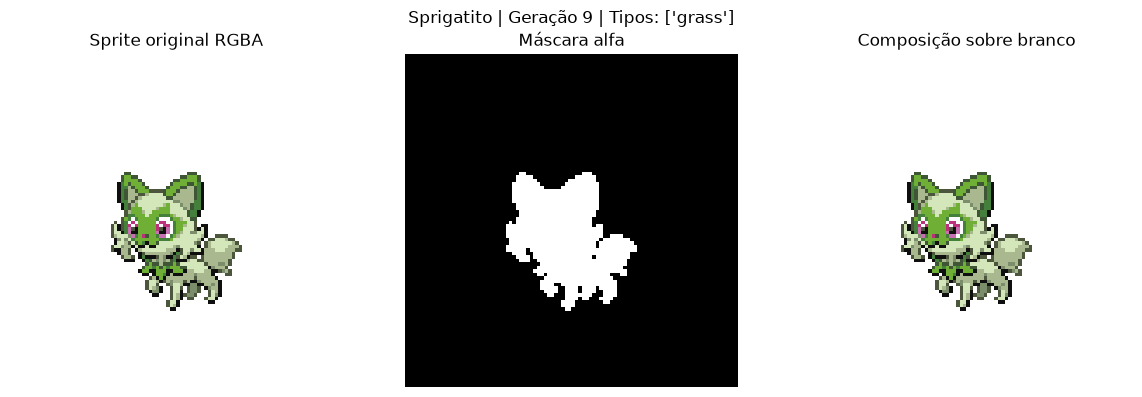

In [17]:
sample_ids = (
    df_pokemon.groupby("generation_number")
    .first()["id"]
    .tolist()
)

for pokemon_id in sample_ids:

    pokemon = df_pokemon[
        df_pokemon["id"] == pokemon_id
    ].iloc[0]

    if pd.notna(pokemon["raw_path"]):

        inspect_sprite(int(pokemon_id))

In [18]:
def process_sprite(
    image,
    image_size=64,
    margin=4
):

    # Garantir formato RGBA
    image = image.convert("RGBA")

    # Extrair canal alfa
    alpha = image.getchannel("A")

    # Identificar região visível
    bbox = alpha.getbbox()

    if bbox is None:
        return None

    # Recortar o sprite utilizando a região visível
    image = image.crop(bbox)

    original_width, original_height = image.size

    # Espaço disponível para o sprite
    available_size = image_size - 2 * margin

    # Preservar proporção
    scale = min(
        available_size / original_width,
        available_size / original_height
    )

    new_width = max(
        1,
        round(original_width * scale)
    )

    new_height = max(
        1,
        round(original_height * scale)
    )

    # Redimensionar preservando pixel art
    image = image.resize(
        (new_width, new_height),
        resample=Image.Resampling.NEAREST
    )

    # Criar fundo branco RGBA
    background = Image.new(
        "RGBA",
        (image_size, image_size),
        (255, 255, 255, 255)
    )

    # Centralizar sprite
    x_offset = (image_size - new_width) // 2
    y_offset = (image_size - new_height) // 2

    # Composição utilizando o canal alfa
    background.alpha_composite(
        image,
        (x_offset, y_offset)
    )

    # Converter para tons de cinza
    grayscale = background.convert("L")

    return grayscale

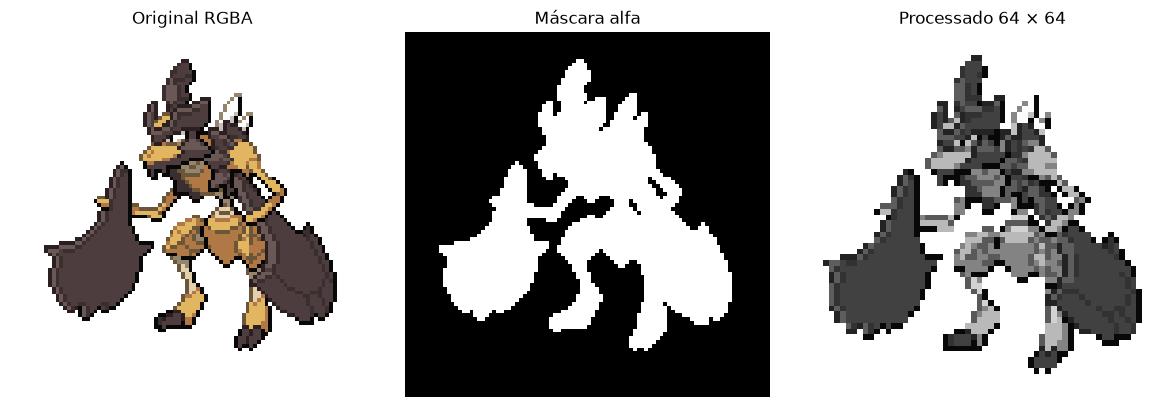

Dimensão original: (96, 96)
Dimensão processada: (64, 64)
Modo processado: L


In [25]:
pokemon_id = 900

pokemon = df_pokemon[
    df_pokemon["id"] == pokemon_id
].iloc[0]

original = Image.open(
    pokemon["raw_path"]
).convert("RGBA")

processed = process_sprite(original)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(original)
axes[0].set_title("Original RGBA")

axes[1].imshow(
    original.getchannel("A"),
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[1].set_title("Máscara alfa")

axes[2].imshow(processed, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Processado 64 × 64")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Dimensão original:", original.size)
print("Dimensão processada:", processed.size)
print("Modo processado:", processed.mode)

In [26]:
for column in ["raw_path", "download_status", "processed_path", "processing_status"]:

    if column in df_pokemon.columns:
        df_pokemon = df_pokemon.drop(columns=column)

In [27]:
raw_paths = []
processed_paths = []
processing_status = []

for _, row in tqdm(
    df_pokemon.iterrows(),
    total=len(df_pokemon)
):

    pokemon_id = int(row["id"])
    pokemon_name = row["pokemon_name"]

    filename = f"{pokemon_id:04d}_{pokemon_name}.png"

    raw_path = RAW_DIR / filename
    processed_path = PROCESSED_DIR / filename

    raw_paths.append(
        str(raw_path) if raw_path.exists() else None
    )

    if not raw_path.exists():

        processed_paths.append(None)
        processing_status.append("missing_raw")
        continue

    # Não processar novamente se o resultado já existir
    if processed_path.exists():

        try:
            with Image.open(processed_path) as image:
                image.verify()

            processed_paths.append(str(processed_path))
            processing_status.append("already_exists")

            continue

        except Exception:
            processed_path.unlink()

    try:

        original = Image.open(raw_path).convert("RGBA")

        processed = process_sprite(
            original,
            image_size=IMAGE_SIZE,
            margin=MARGIN
        )

        if processed is None:

            processed_paths.append(None)
            processing_status.append("empty_sprite")

            continue

        processed.save(
            processed_path,
            format="PNG"
        )

        processed_paths.append(str(processed_path))
        processing_status.append("processed")

    except Exception as error:

        processed_paths.append(None)
        processing_status.append(f"error: {error}")


df_pokemon["raw_path"] = raw_paths
df_pokemon["processed_path"] = processed_paths
df_pokemon["processing_status"] = processing_status

# Salvar tipos em formato consistente no CSV
metadata_to_save = df_pokemon.copy()

metadata_to_save["types"] = metadata_to_save["types"].apply(
    lambda types: "|".join(types)
)

metadata_to_save.to_csv(
    METADATA_PATH,
    index=False
)

print("Resumo do processamento:")

display(
    df_pokemon["processing_status"]
    .value_counts()
    .to_frame("quantidade")
)

print(
    "\nSprites processados:",
    df_pokemon["processed_path"].notna().sum()
)

  0%|          | 0/1025 [00:00<?, ?it/s]

Resumo do processamento:


,quantidade
processing_status,
processed,1025



Sprites processados: 1025


Processamento das imagens

In [28]:
def compare_processed_sprite(pokemon_id):

    pokemon = df_pokemon[
        df_pokemon["id"] == pokemon_id
    ].iloc[0]

    original = Image.open(
        pokemon["raw_path"]
    ).convert("RGBA")

    alpha = original.getchannel("A")

    processed = Image.open(
        pokemon["processed_path"]
    ).convert("L")

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(original)
    axes[0].set_title("Original")

    axes[1].imshow(
        alpha,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1].set_title("Máscara alfa")

    axes[2].imshow(
        processed,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[2].set_title("Processado")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"{pokemon['pokemon_name'].capitalize()} | "
        f"Geração {pokemon['generation_number']} | "
        f"Tipos: {pokemon['types']}"
    )

    plt.tight_layout()
    plt.show()

    print("Original:", original.size, original.mode)
    print("Processado:", processed.size, processed.mode)
    print("Mínimo:", np.array(processed).min())
    print("Máximo:", np.array(processed).max())

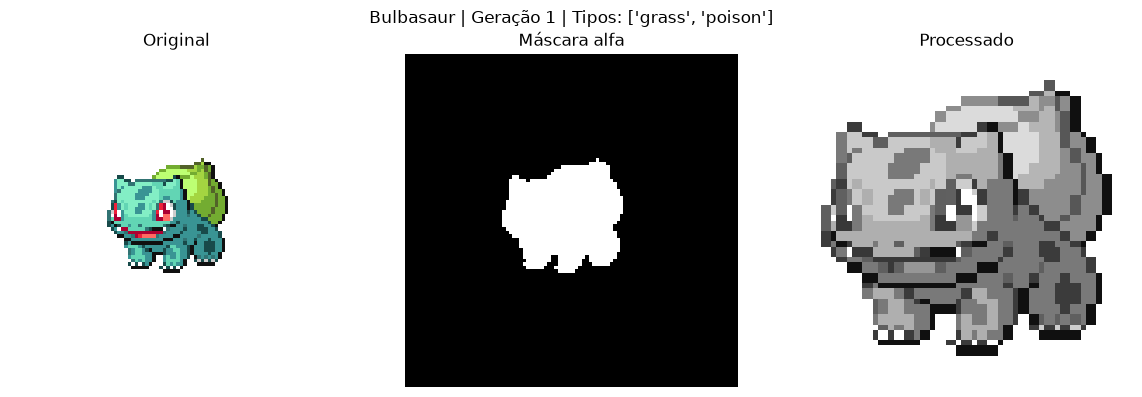

Original: (96, 96) RGBA
Processado: (64, 64) L
Mínimo: 16
Máximo: 255


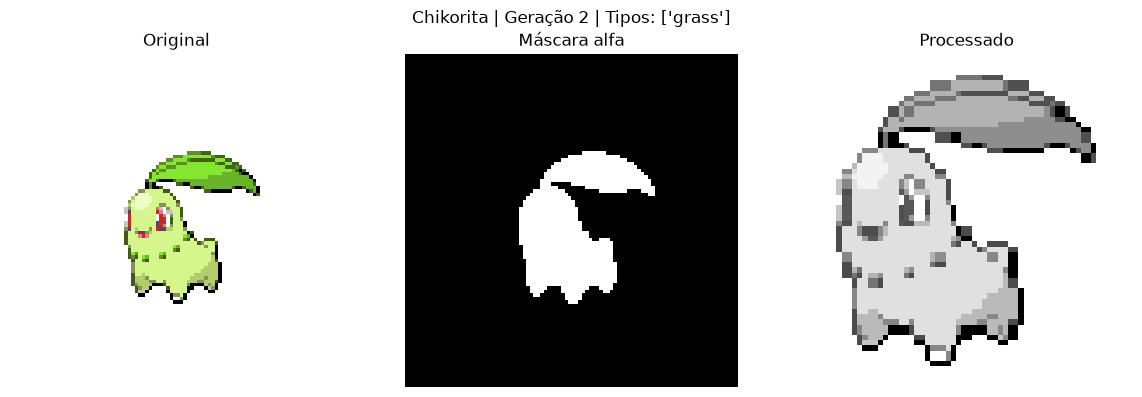

Original: (96, 96) RGBA
Processado: (64, 64) L
Mínimo: 0
Máximo: 255


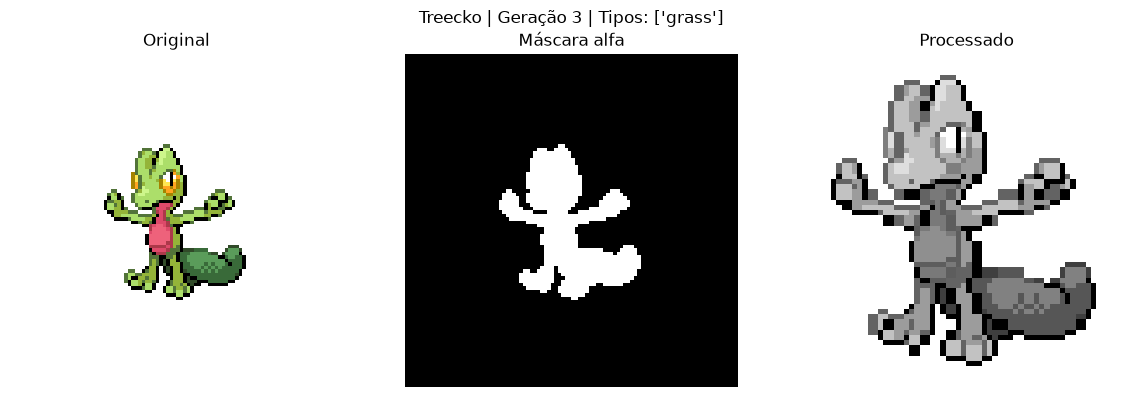

Original: (96, 96) RGBA
Processado: (64, 64) L
Mínimo: 0
Máximo: 255


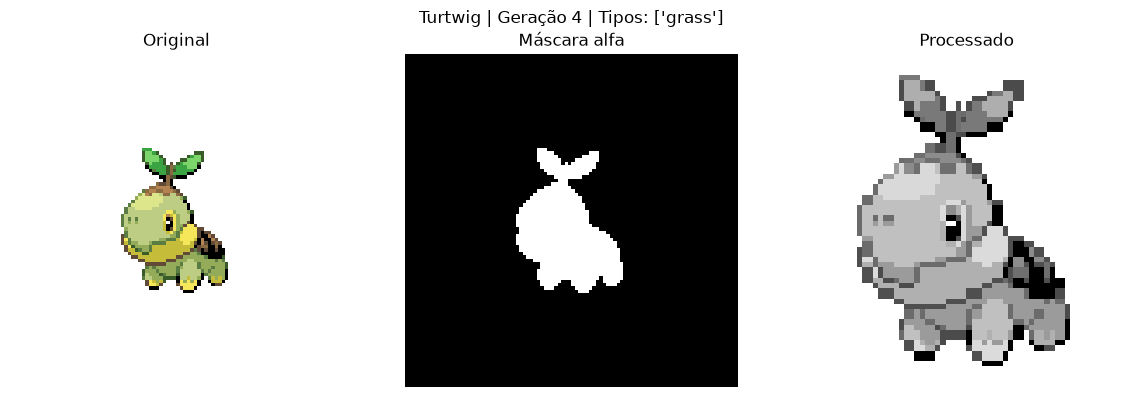

Original: (96, 96) RGBA
Processado: (64, 64) L
Mínimo: 0
Máximo: 255


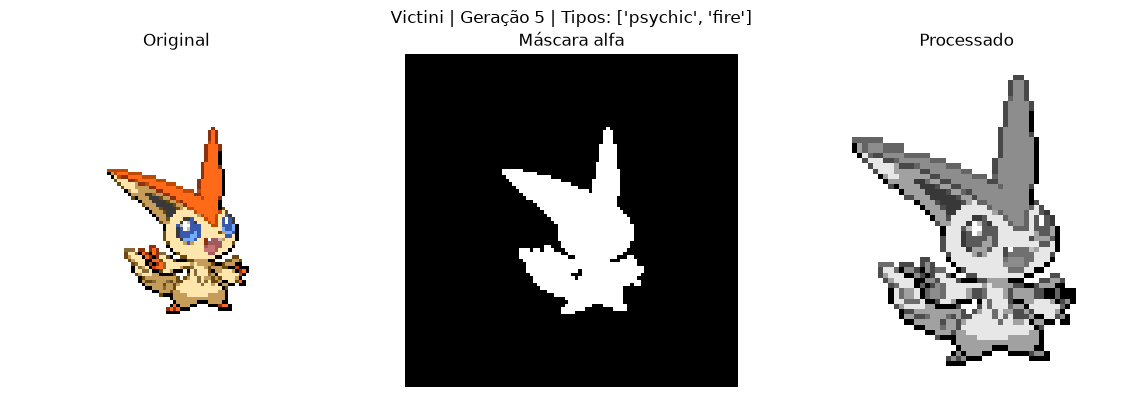

Original: (96, 96) RGBA
Processado: (64, 64) L
Mínimo: 0
Máximo: 255


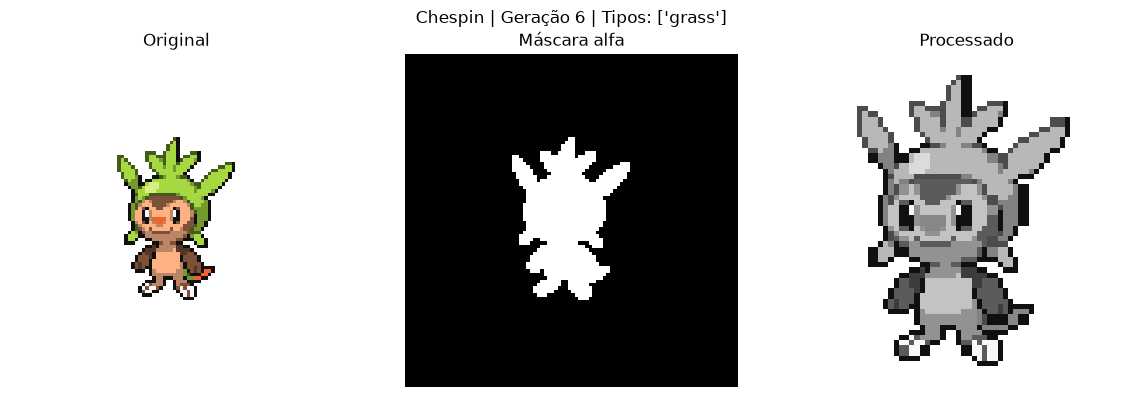

Original: (96, 96) RGBA
Processado: (64, 64) L
Mínimo: 16
Máximo: 255


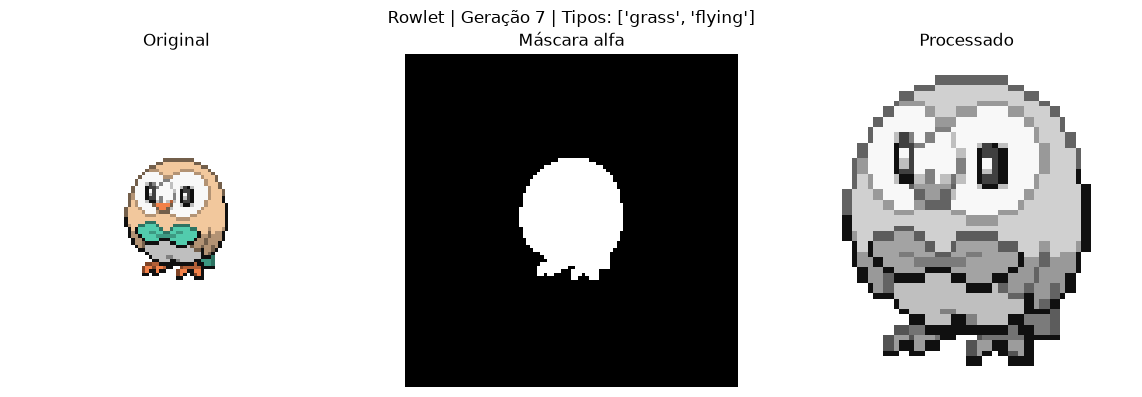

Original: (96, 96) RGBA
Processado: (64, 64) L
Mínimo: 16
Máximo: 255


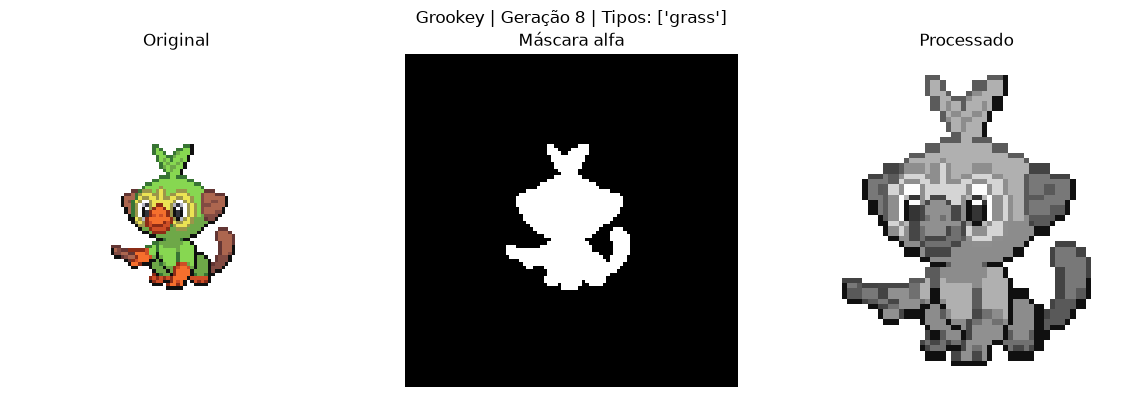

Original: (96, 96) RGBA
Processado: (64, 64) L
Mínimo: 16
Máximo: 255


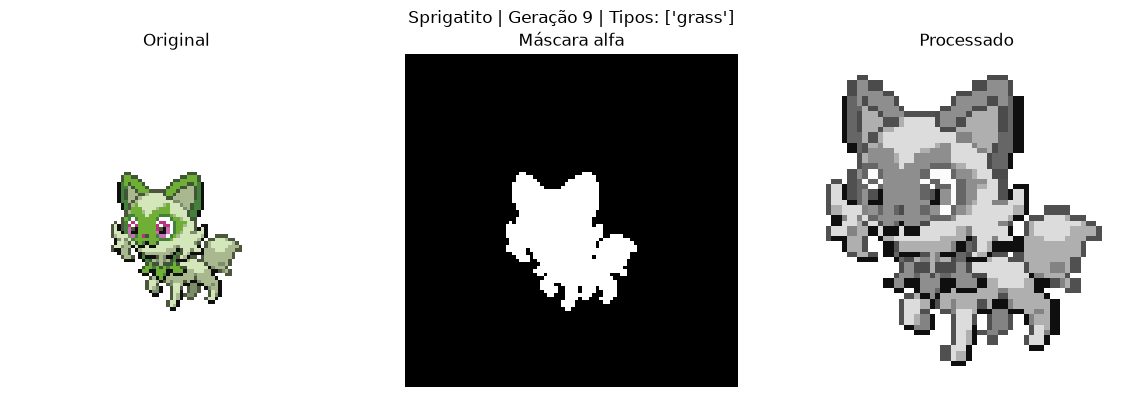

Original: (96, 96) RGBA
Processado: (64, 64) L
Mínimo: 15
Máximo: 255


In [29]:
sample_ids = (
    df_pokemon.groupby("generation_number")
    .first()["id"]
    .tolist()
)

for pokemon_id in sample_ids:

    pokemon = df_pokemon[
        df_pokemon["id"] == pokemon_id
    ].iloc[0]

    if pd.notna(pokemon["processed_path"]):

        compare_processed_sprite(int(pokemon_id))

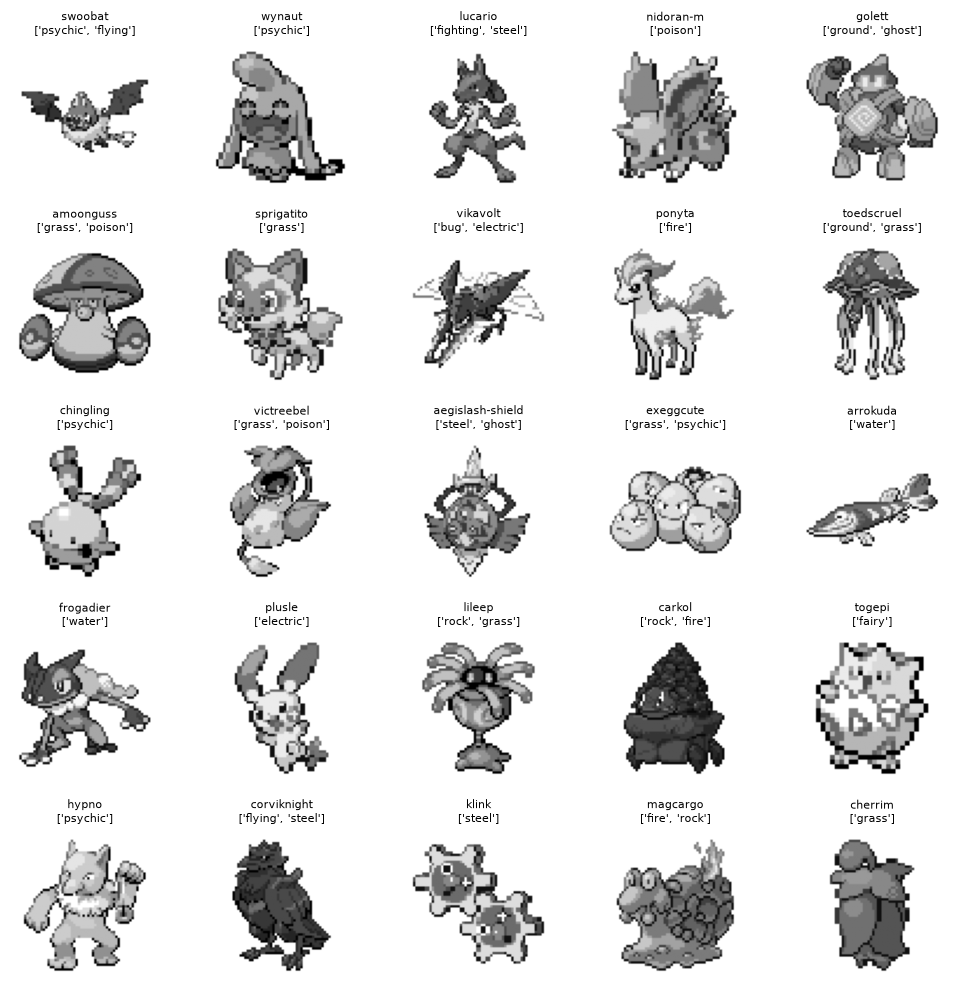

In [30]:
sample_df = df_pokemon[
    df_pokemon["processed_path"].notna()
].sample(
    n=min(25, df_pokemon["processed_path"].notna().sum()),
    random_state=SEED
)

fig, axes = plt.subplots(5, 5, figsize=(10, 10))

for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):

    image = Image.open(
        row["processed_path"]
    ).convert("L")

    ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    ax.set_title(
        f"{row['pokemon_name']}\n{row['types']}",
        fontsize=8
    )

    ax.axis("off")

for ax in axes.flat[len(sample_df):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Seração de conjuntos 

In [31]:
latest_generation = int(
    df_pokemon["generation_number"].max()
)

print("Última geração encontrada:", latest_generation)

print(
    "Nome:",
    df_pokemon[
        df_pokemon["generation_number"] == latest_generation
    ]["generation"].iloc[0]
)

Última geração encontrada: 9
Nome: generation-ix


In [32]:
df_valid = df_pokemon[
    df_pokemon["processed_path"].notna()
].copy()

# Separar gerações anteriores e última geração
df_train = df_valid[
    df_valid["generation_number"] < latest_generation
].copy()

df_latest = df_valid[
    df_valid["generation_number"] == latest_generation
].copy()

print("Gerações anteriores:", len(df_train))
print("Última geração:", len(df_latest))

Gerações anteriores: 905
Última geração: 120


In [33]:
rng = np.random.default_rng(SEED)

latest_indices = np.arange(len(df_latest))

rng.shuffle(latest_indices)

n_val = len(latest_indices) // 2

val_indices = latest_indices[:n_val]
test_indices = latest_indices[n_val:]

df_val = df_latest.iloc[val_indices].copy()
df_test = df_latest.iloc[test_indices].copy()

# Identificar a divisão
df_train["split"] = "train"
df_val["split"] = "validation"
df_test["split"] = "test"

# Juntar tudo
df_split = pd.concat(
    [df_train, df_val, df_test],
    ignore_index=True
)

df_split.to_csv(
    SPLIT_PATH,
    index=False
)

In [34]:
print("Distribuição dos conjuntos:")

display(
    df_split.groupby(
        ["split", "generation_number"]
    ).size().to_frame("quantidade")
)

print("\nTotal por conjunto:")

display(
    df_split["split"].value_counts().to_frame("quantidade")
)

Distribuição dos conjuntos:


quantidade
split      generation_number            
test       9                          60
train      1                         151
           2                         100
           3                         135
           4                         107
           5                         156
           6                          72
           7                          88
           8                          96
validation 9                          60


Total por conjunto:


,quantidade
split,
train,905
validation,60
test,60


In [35]:
assert (
    df_train["generation_number"] < latest_generation
).all()

assert (
    df_val["generation_number"] == latest_generation
).all()

assert (
    df_test["generation_number"] == latest_generation
).all()

assert set(df_train["id"]).isdisjoint(set(df_val["id"]))
assert set(df_train["id"]).isdisjoint(set(df_test["id"]))
assert set(df_val["id"]).isdisjoint(set(df_test["id"]))

print("Todas as verificações da divisão passaram!")

Todas as verificações da divisão passaram!


Preparação do metadados

In [36]:
POKEMON_TYPES = [
    "normal",
    "fire",
    "water",
    "electric",
    "grass",
    "ice",
    "fighting",
    "poison",
    "ground",
    "flying",
    "psychic",
    "bug",
    "rock",
    "ghost",
    "dragon",
    "dark",
    "steel",
    "fairy"
]

TYPE_TO_IDX = {
    pokemon_type: idx
    for idx, pokemon_type in enumerate(POKEMON_TYPES)
}

NUM_TYPES = len(POKEMON_TYPES)

print("Quantidade de tipos:", NUM_TYPES)
print(TYPE_TO_IDX)

Quantidade de tipos: 18
{'normal': 0, 'fire': 1, 'water': 2, 'electric': 3, 'grass': 4, 'ice': 5, 'fighting': 6, 'poison': 7, 'ground': 8, 'flying': 9, 'psychic': 10, 'bug': 11, 'rock': 12, 'ghost': 13, 'dragon': 14, 'dark': 15, 'steel': 16, 'fairy': 17}


In [37]:
def encode_types(types):

    encoding = np.zeros(
        NUM_TYPES,
        dtype=np.float32
    )

    for pokemon_type in types:

        if pokemon_type not in TYPE_TO_IDX:

            raise ValueError(
                f"Tipo desconhecido: {pokemon_type}"
            )

        idx = TYPE_TO_IDX[pokemon_type]

        encoding[idx] = 1.0

    return encoding

In [38]:
examples = ["charizard", "pikachu", "bulbasaur", "gyarados"]

for name in examples:

    row = df_pokemon[
        df_pokemon["pokemon_name"] == name
    ].iloc[0]

    encoding = encode_types(row["types"])

    active_types = [
        POKEMON_TYPES[i]
        for i in np.where(encoding == 1)[0]
    ]

    print(f"\n{name.capitalize()}")
    print("Tipos:", active_types)
    print("Encoding:", encoding)
    print("Shape:", encoding.shape)


Charizard
Tipos: ['fire', 'flying']
Encoding: [0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
Shape: (18,)

Pikachu
Tipos: ['electric']
Encoding: [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Shape: (18,)

Bulbasaur
Tipos: ['grass', 'poison']
Encoding: [0. 0. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Shape: (18,)

Gyarados
Tipos: ['water', 'flying']
Encoding: [0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
Shape: (18,)


In [40]:
for name, subset in [
    ("Treinamento", df_train),
    ("Validação", df_val),
    ("Teste", df_test)
]:

    counter = Counter(
        pokemon_type
        for types in subset["types"]
        for pokemon_type in types
    )

    print(f"\n{name}")

    display(
        pd.Series(counter)
        .reindex(POKEMON_TYPES, fill_value=0)
        .to_frame("quantidade")
    )


Treinamento


,quantidade
normal,117
fire,71
water,142
electric,57
grass,107
ice,41
fighting,62
poison,71
ground,68
flying,103



Validação


,quantidade
normal,8
fire,7
water,4
electric,5
grass,12
ice,2
fighting,4
poison,8
ground,3
flying,2



Teste


,quantidade
normal,6
fire,3
water,8
electric,7
grass,8
ice,5
fighting,7
poison,4
ground,4
flying,4


In [41]:
def type_combination(types):

    return " / ".join(sorted(types))


df_split["type_combination"] = df_split["types"].apply(
    type_combination
)

print("Combinações mais frequentes no treinamento:")

display(
    df_split[df_split["split"] == "train"]
    ["type_combination"]
    .value_counts()
    .head(20)
    .to_frame("quantidade")
)

print("\nCombinações da validação:")

display(
    df_split[df_split["split"] == "validation"]
    ["type_combination"]
    .value_counts()
    .to_frame("quantidade")
)

print("\nCombinações do teste:")

display(
    df_split[df_split["split"] == "test"]
    ["type_combination"]
    .value_counts()
    .to_frame("quantidade")
)

Combinações mais frequentes no treinamento:


,quantidade
type_combination,
normal,69
water,67
grass,43
psychic,37
fire,33
electric,32
fighting,28
flying / normal,26
bug,19



Combinações da validação:


,quantidade
type_combination,
dark / grass,3
water,3
fire,3
grass,3
normal,3
rock,3
fairy,2
dragon / grass,2
normal / poison,2



Combinações do teste:


,quantidade
type_combination,
water,4
bug,4
normal,3
ghost / grass,3
grass / ground,2
fire / ghost,2
dragon / water,2
electric / fighting,2
dragon / ice,2


Processamnto para dataloader (começar a rodar daqui o notebook agora)

In [10]:
import ast

def parse_types(value):

    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    value = str(value).strip()

    # Caso seja uma representação de lista Python
    if value.startswith("["):
        return ast.literal_eval(value)

    # Caso esteja separado por |
    return value.split("|")

In [12]:
import torch
from torch.utils.data import Dataset

from PIL import Image

class PokemonDataset(Dataset):

    def __init__(self, dataframe):

        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        # Carregar imagem
        image = Image.open(
            row["processed_path"]
        ).convert("L")

        image = np.array(
            image,
            dtype=np.float32
        ) / 255.0

        # Transformar em tensor: [1, 64, 64]
        image = torch.from_numpy(image).unsqueeze(0)

        # Criar condição Multi-Hot
        condition = torch.zeros(
            NUM_TYPES,
            dtype=torch.float32
        )

        for pokemon_type in row["types"]:

            type_idx = TYPE_TO_IDX[pokemon_type]

            condition[type_idx] = 1.0

        return image, condition

Conserto

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

# Diretório do projeto
BASE_DIR = Path("poke_sprite")

# Arquivo com os metadados e a divisão dos conjuntos
CSV_PATH = BASE_DIR / "dataset_split.csv"

# Conferir os arquivos
print("Diretório:", BASE_DIR.resolve())
print("CSV encontrado:", CSV_PATH.exists())

# Carregar metadados
df_split = pd.read_csv(CSV_PATH)

print("\nQuantidade de registros:", len(df_split))
print("\nColunas:")
print(df_split.columns.tolist())

display(df_split.head())

Diretório: C:\Mestrado\VAE\poke_sprite
CSV encontrado: True

Quantidade de registros: 1025

Colunas:
['id', 'name', 'pokemon_name', 'generation', 'generation_number', 'types', 'num_types', 'sprite_url', 'raw_path', 'processed_path', 'processing_status', 'split']


,id,name,pokemon_name,generation,generation_number,types,num_types,sprite_url,raw_path,processed_path,processing_status,split
0,1,bulbasaur,bulbasaur,generation-i,1,"['grass', 'poison']",2,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0001_bulbasaur.png,poke_sprite\processed\0001_bulbasaur.png,processed,train
1,2,ivysaur,ivysaur,generation-i,1,"['grass', 'poison']",2,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0002_ivysaur.png,poke_sprite\processed\0002_ivysaur.png,processed,train
2,3,venusaur,venusaur,generation-i,1,"['grass', 'poison']",2,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0003_venusaur.png,poke_sprite\processed\0003_venusaur.png,processed,train
3,4,charmander,charmander,generation-i,1,['fire'],1,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0004_charmander.png,poke_sprite\processed\0004_charmander.png,processed,train
4,5,charmeleon,charmeleon,generation-i,1,['fire'],1,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0005_charmeleon.png,poke_sprite\processed\0005_charmeleon.png,processed,train


In [48]:
print("Sprites originais encontrados:")

existing_files = df_split["raw_path"].apply(
    lambda path: Path(path).exists()
)

print(existing_files.sum(), "/", len(df_split))

print("\nArquivos ausentes:")
display(
    df_split.loc[
        ~existing_files,
        ["pokemon_name", "raw_path"]
    ].head(10)
)

Sprites originais encontrados:
1025 / 1025

Arquivos ausentes:


,pokemon_name,raw_path


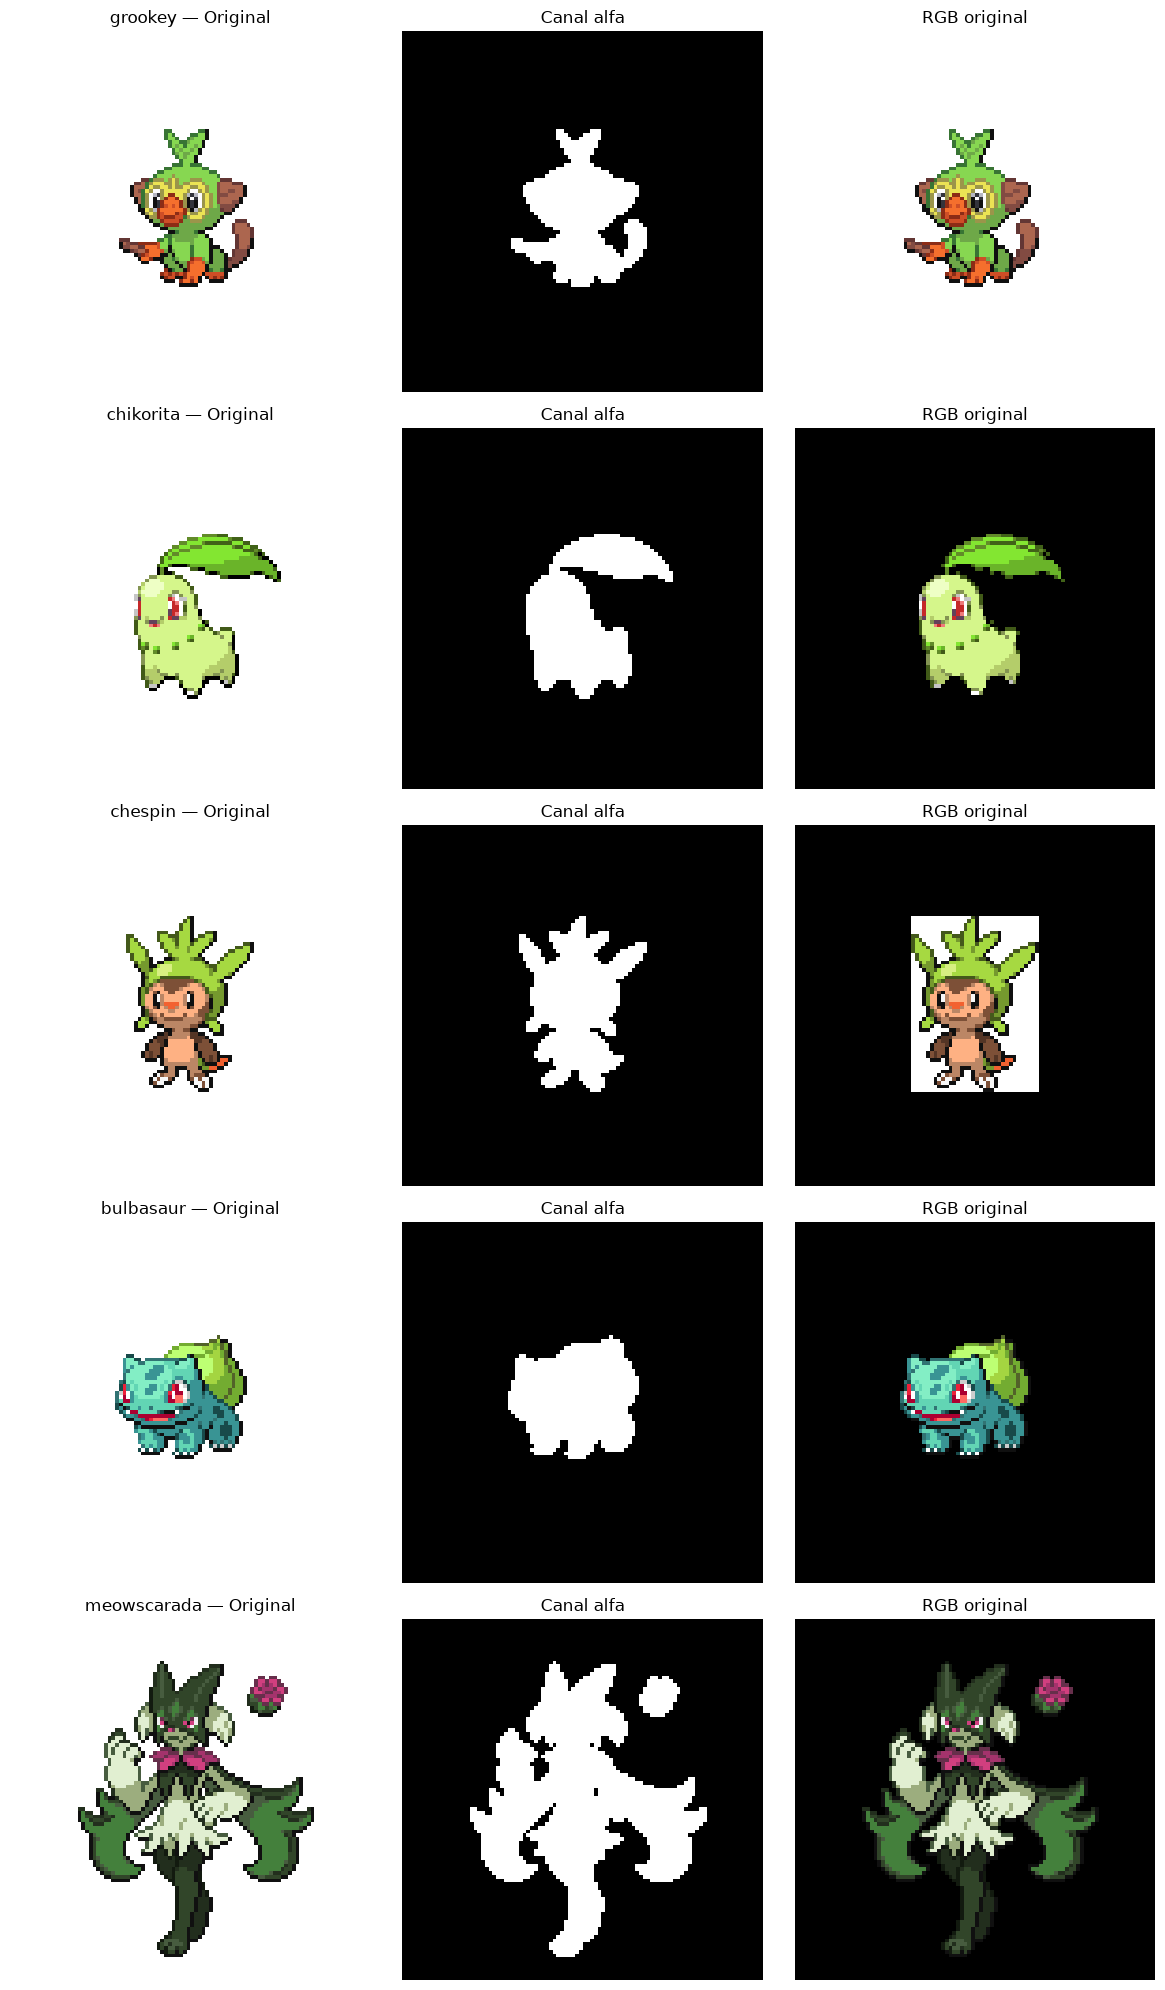

In [49]:
samples = df_split.groupby("generation_number").first()

selected_samples = samples.sample(
    n=min(5, len(samples)),
    random_state=42
)

fig, axes = plt.subplots(
    len(selected_samples),
    3,
    figsize=(12, 4 * len(selected_samples))
)

if len(selected_samples) == 1:
    axes = np.expand_dims(axes, axis=0)

for i, (_, row) in enumerate(selected_samples.iterrows()):

    image = Image.open(row["raw_path"]).convert("RGBA")

    rgba = np.array(image)

    rgb = rgba[:, :, :3]
    alpha = rgba[:, :, 3]

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(
        f"{row['pokemon_name']} — Original"
    )

    axes[i, 1].imshow(
        alpha,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[i, 1].set_title("Canal alfa")

    axes[i, 2].imshow(
        rgb
    )
    axes[i, 2].set_title("RGB original")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [50]:
for _, row in selected_samples.iterrows():

    image = Image.open(row["raw_path"]).convert("RGBA")

    rgba = np.array(image)
    alpha = rgba[:, :, 3]

    print(f"\nPokémon: {row['pokemon_name']}")
    print("Dimensões:", image.size)
    print("Alpha mínimo:", alpha.min())
    print("Alpha máximo:", alpha.max())
    print("Pixels transparentes:", np.sum(alpha == 0))
    print("Pixels parcialmente transparentes:",
          np.sum((alpha > 0) & (alpha < 255)))
    print("Pixels opacos:", np.sum(alpha == 255))
    print("Valores únicos de alpha:", np.unique(alpha)[:20])


Pokémon: grookey
Dimensões: (96, 96)
Alpha mínimo: 0
Alpha máximo: 255
Pixels transparentes: 8402
Pixels parcialmente transparentes: 0
Pixels opacos: 814
Valores únicos de alpha: [  0 255]

Pokémon: chikorita
Dimensões: (96, 96)
Alpha mínimo: 0
Alpha máximo: 255
Pixels transparentes: 8313
Pixels parcialmente transparentes: 0
Pixels opacos: 903
Valores únicos de alpha: [  0 255]

Pokémon: chespin
Dimensões: (96, 96)
Alpha mínimo: 0
Alpha máximo: 255
Pixels transparentes: 8347
Pixels parcialmente transparentes: 0
Pixels opacos: 869
Valores únicos de alpha: [  0 255]

Pokémon: bulbasaur
Dimensões: (96, 96)
Alpha mínimo: 0
Alpha máximo: 255
Pixels transparentes: 8370
Pixels parcialmente transparentes: 0
Pixels opacos: 846
Valores únicos de alpha: [  0 255]

Pokémon: meowscarada
Dimensões: (96, 96)
Alpha mínimo: 0
Alpha máximo: 255
Pixels transparentes: 7013
Pixels parcialmente transparentes: 0
Pixels opacos: 2203
Valores únicos de alpha: [  0 255]


In [51]:
def inspect_opaque_background(row):

    image = Image.open(row["raw_path"]).convert("RGBA")
    rgba = np.array(image)

    rgb = rgba[:, :, :3]
    alpha = rgba[:, :, 3]

    # Pixels opacos
    opaque = alpha > 0

    # Pixels quase brancos
    white = (
        (rgb[:, :, 0] >= 245) &
        (rgb[:, :, 1] >= 245) &
        (rgb[:, :, 2] >= 245)
    )

    # Pixels brancos dentro da região opaca
    opaque_white = opaque & white

    print(f"Pokémon: {row['pokemon_name']}")
    print("Pixels opacos:", opaque.sum())
    print("Pixels brancos opacos:", opaque_white.sum())

    if opaque.sum() > 0:
        percentage = opaque_white.sum() / opaque.sum() * 100
        print(f"Percentual branco opaco: {percentage:.2f}%")

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(image)
    axes[0].set_title("Original RGBA")

    axes[1].imshow(opaque, cmap="gray")
    axes[1].set_title("Máscara alfa")

    axes[2].imshow(opaque_white, cmap="gray")
    axes[2].set_title("Pixels brancos opacos")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

Pokémon: grookey
Pixels opacos: 814
Pixels brancos opacos: 14
Percentual branco opaco: 1.72%


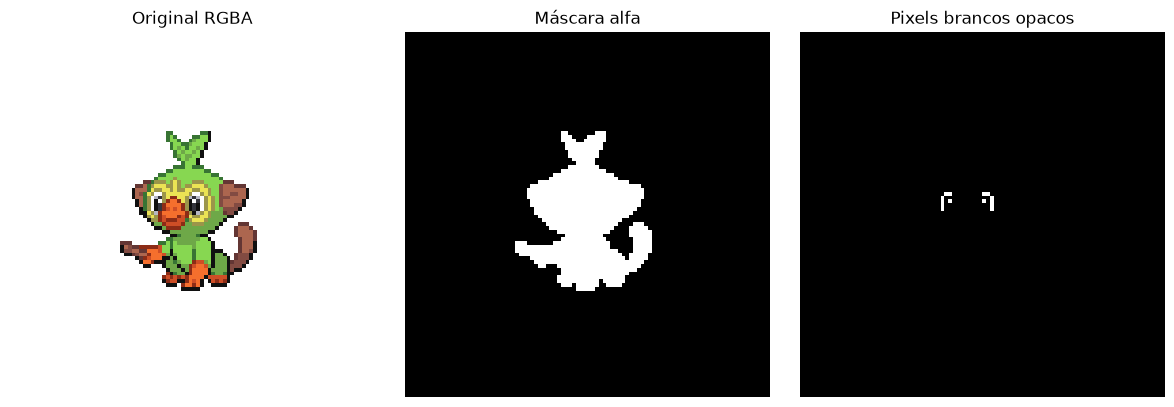

Pokémon: chikorita
Pixels opacos: 903
Pixels brancos opacos: 12
Percentual branco opaco: 1.33%


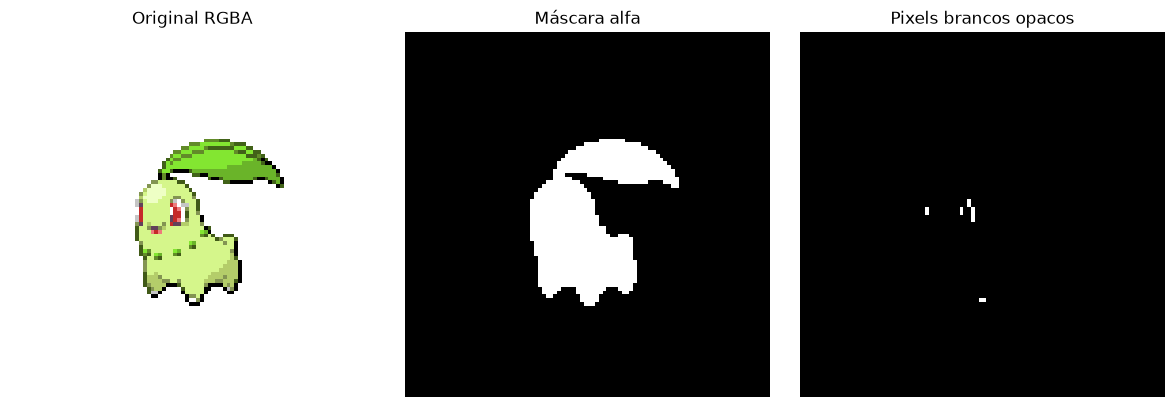

Pokémon: chespin
Pixels opacos: 869
Pixels brancos opacos: 18
Percentual branco opaco: 2.07%


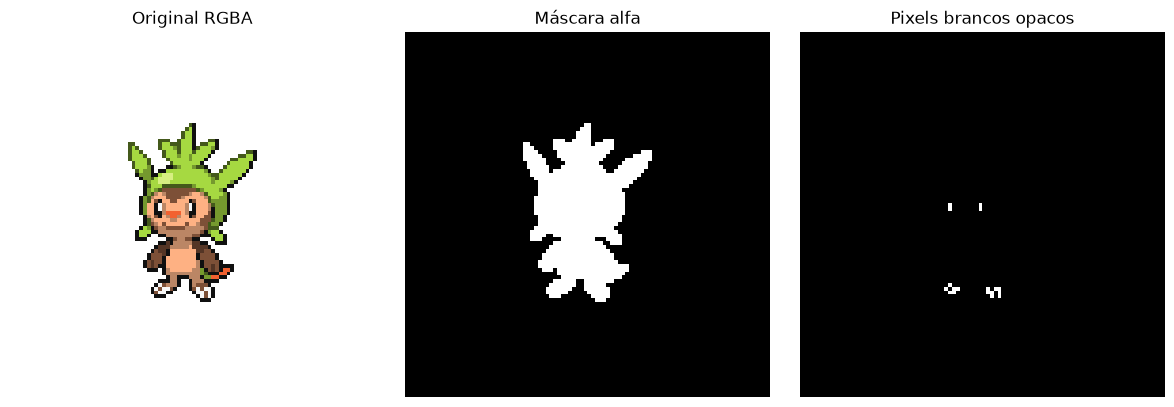

Pokémon: bulbasaur
Pixels opacos: 846
Pixels brancos opacos: 17
Percentual branco opaco: 2.01%


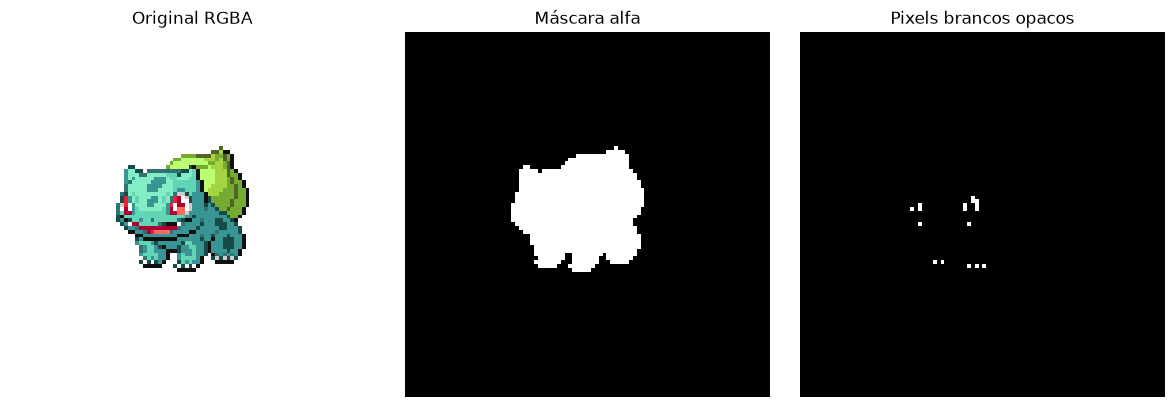

Pokémon: meowscarada
Pixels opacos: 2203
Pixels brancos opacos: 0
Percentual branco opaco: 0.00%


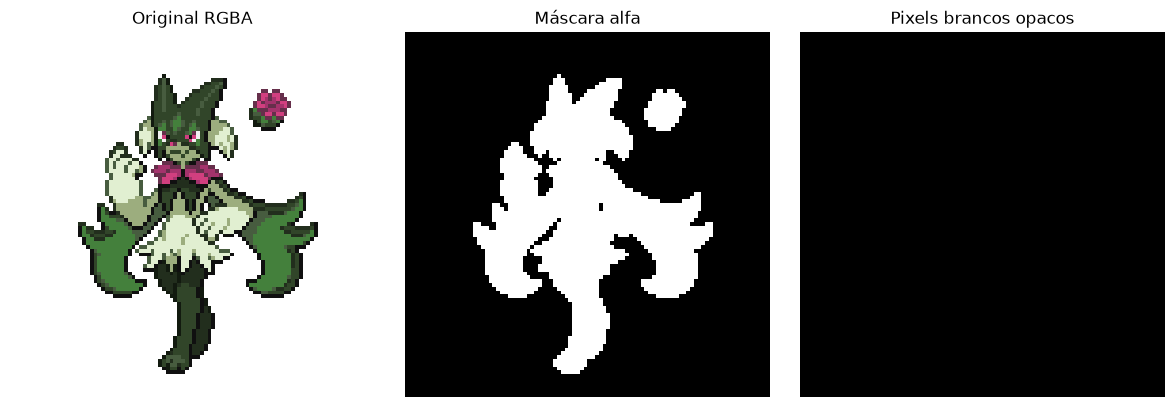

In [52]:
for _, row in selected_samples.iterrows():

    inspect_opaque_background(row)

In [54]:
from pathlib import Path
from PIL import Image

BASE_DIR = Path("poke_sprite")

RAW_DIR = BASE_DIR / "raw"
IMAGE_DIR = BASE_DIR / "processed_masked"
MASK_DIR = BASE_DIR / "masks"

IMAGE_DIR.mkdir(parents=True, exist_ok=True)
MASK_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 64
MARGIN = 4

print("Sprites originais:", RAW_DIR.resolve())
print("Novas imagens:", IMAGE_DIR.resolve())
print("Novas máscaras:", MASK_DIR.resolve())

Sprites originais: C:\Mestrado\VAE\poke_sprite\raw
Novas imagens: C:\Mestrado\VAE\poke_sprite\processed_masked
Novas máscaras: C:\Mestrado\VAE\poke_sprite\masks


In [55]:
import numpy as np
from PIL import Image


def process_sprite_masked(
    raw_path,
    image_size=64,
    margin=4
):

    # Carregar sprite original
    rgba = Image.open(raw_path).convert("RGBA")

    # Separar RGB e alfa
    alpha = rgba.getchannel("A")

    # Encontrar região visível
    bbox = alpha.getbbox()

    if bbox is None:
        raise ValueError("Sprite sem pixels visíveis.")

    # Recortar imagem e máscara com a mesma região
    rgba = rgba.crop(bbox)
    alpha = alpha.crop(bbox)

    # Converter RGB para escala de cinza
    gray = rgba.convert("L")

    original_width, original_height = gray.size

    # Dimensão disponível
    available_size = image_size - 2 * margin

    # Preservar proporção
    scale = min(
        available_size / original_width,
        available_size / original_height
    )

    new_width = max(1, round(original_width * scale))
    new_height = max(1, round(original_height * scale))

    new_size = (new_width, new_height)

    # Redimensionar imagem e máscara
    gray = gray.resize(
        new_size,
        Image.Resampling.NEAREST
    )

    alpha = alpha.resize(
        new_size,
        Image.Resampling.NEAREST
    )

    # Criar canvases com fundo zero
    image_canvas = Image.new(
        "L",
        (image_size, image_size),
        0
    )

    mask_canvas = Image.new(
        "L",
        (image_size, image_size),
        0
    )

    # Calcular posição centralizada
    x_offset = (image_size - new_width) // 2
    y_offset = (image_size - new_height) // 2

    # Inserir imagem e máscara
    image_canvas.paste(
        gray,
        (x_offset, y_offset)
    )

    mask_canvas.paste(
        alpha,
        (x_offset, y_offset)
    )

    # Garantir que regiões transparentes não contenham intensidades
    image_array = np.array(image_canvas, dtype=np.uint8)
    mask_array = np.array(mask_canvas, dtype=np.uint8)

    image_array[mask_array == 0] = 0

    image_canvas = Image.fromarray(image_array)

    return image_canvas, mask_canvas

In [53]:
IMAGE_SIZE = 64
MARGIN = 4

def resize_sprite_and_mask(image, mask):

    # Bounding box da região opaca
    bbox = mask.getbbox()

    if bbox is None:
        raise ValueError("Sprite sem pixels opacos.")

    image = image.crop(bbox)
    mask = mask.crop(bbox)

    original_width, original_height = image.size

    available_size = IMAGE_SIZE - 2 * MARGIN

    scale = min(
        available_size / original_width,
        available_size / original_height
    )

    new_width = max(1, round(original_width * scale))
    new_height = max(1, round(original_height * scale))

    new_size = (new_width, new_height)

    image = image.resize(
        new_size,
        Image.Resampling.NEAREST
    )

    mask = mask.resize(
        new_size,
        Image.Resampling.NEAREST
    )

    # Canvas de 64x64
    image_canvas = Image.new(
        "L",
        (IMAGE_SIZE, IMAGE_SIZE),
        0
    )

    mask_canvas = Image.new(
        "L",
        (IMAGE_SIZE, IMAGE_SIZE),
        0
    )

    # Centralização
    x = (IMAGE_SIZE - new_width) // 2
    y = (IMAGE_SIZE - new_height) // 2

    image_canvas.paste(image, (x, y))
    mask_canvas.paste(mask, (x, y))

    return image_canvas, mask_canvas

In [56]:
sample_names = [
    "grookey",
    "chikorita",
    "chespin",
    "bulbasaur",
    "meowscarada"
]

sample_df = df_split[
    df_split["pokemon_name"].isin(sample_names)
]

for _, row in sample_df.iterrows():

    image, mask = process_sprite_masked(
        row["raw_path"]
    )

    print(f"\nPokémon: {row['pokemon_name']}")
    print("Imagem:", image.size, image.mode)
    print("Máscara:", mask.size, mask.mode)

    image_array = np.array(image)
    mask_array = np.array(mask)

    print(
        "Pixels fora da máscara:",
        np.sum(image_array[mask_array == 0] != 0)
    )

    print(
        "Pixels pertencentes ao sprite:",
        np.sum(mask_array > 0)
    )

    print(
        "Valores únicos da máscara:",
        np.unique(mask_array)
    )


Pokémon: bulbasaur
Imagem: (64, 64) L
Máscara: (64, 64) L
Pixels fora da máscara: 0
Pixels pertencentes ao sprite: 2164
Valores únicos da máscara: [  0 255]

Pokémon: chikorita
Imagem: (64, 64) L
Máscara: (64, 64) L
Pixels fora da máscara: 0
Pixels pertencentes ao sprite: 1476
Valores únicos da máscara: [  0 255]

Pokémon: chespin
Imagem: (64, 64) L
Máscara: (64, 64) L
Pixels fora da máscara: 0
Pixels pertencentes ao sprite: 1260
Valores únicos da máscara: [  0 255]

Pokémon: grookey
Imagem: (64, 64) L
Máscara: (64, 64) L
Pixels fora da máscara: 0
Pixels pertencentes ao sprite: 1455
Valores únicos da máscara: [  0 255]

Pokémon: meowscarada
Imagem: (64, 64) L
Máscara: (64, 64) L
Pixels fora da máscara: 0
Pixels pertencentes ao sprite: 1116
Valores únicos da máscara: [  0 255]


In [57]:
def visualize_masked_processing(row):

    image, mask = process_sprite_masked(
        row["raw_path"]
    )

    original = Image.open(
        row["raw_path"]
    ).convert("RGBA")

    image_array = np.array(image, dtype=np.float32) / 255.0
    mask_array = np.array(mask, dtype=np.float32) / 255.0

    # Composição exclusivamente para visualização
    preview = (
        image_array * mask_array
        + (1.0 - mask_array)
    )

    fig, axes = plt.subplots(
        1, 4,
        figsize=(14, 4)
    )

    axes[0].imshow(original)
    axes[0].set_title("Original RGBA")

    axes[1].imshow(
        image_array,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Imagem processada")

    axes[2].imshow(
        mask_array,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[2].set_title("Máscara alfa")

    axes[3].imshow(
        preview,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[3].set_title("Composição (visualização)")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"{row['pokemon_name'].capitalize()} — "
        f"64 × 64"
    )

    plt.tight_layout()
    plt.show()

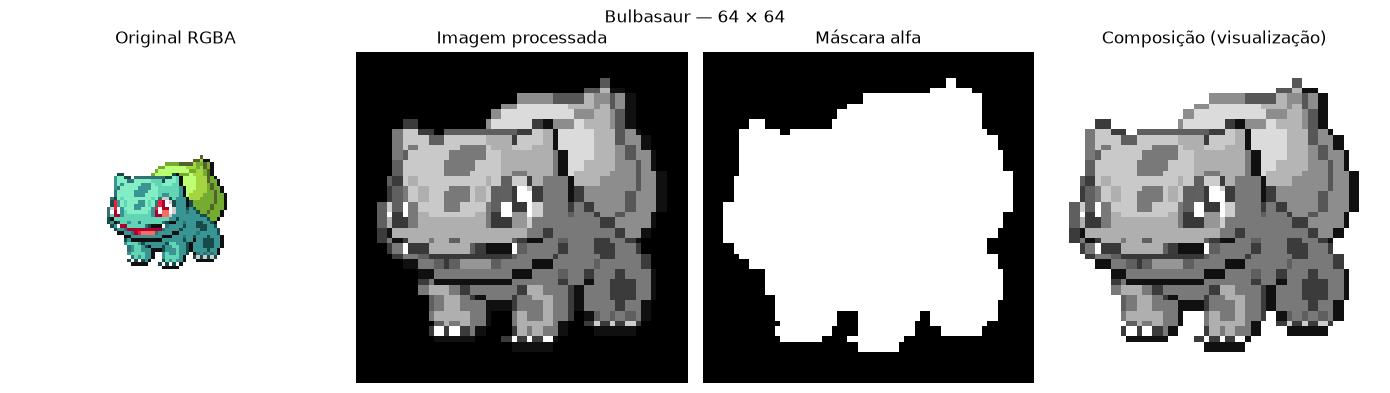

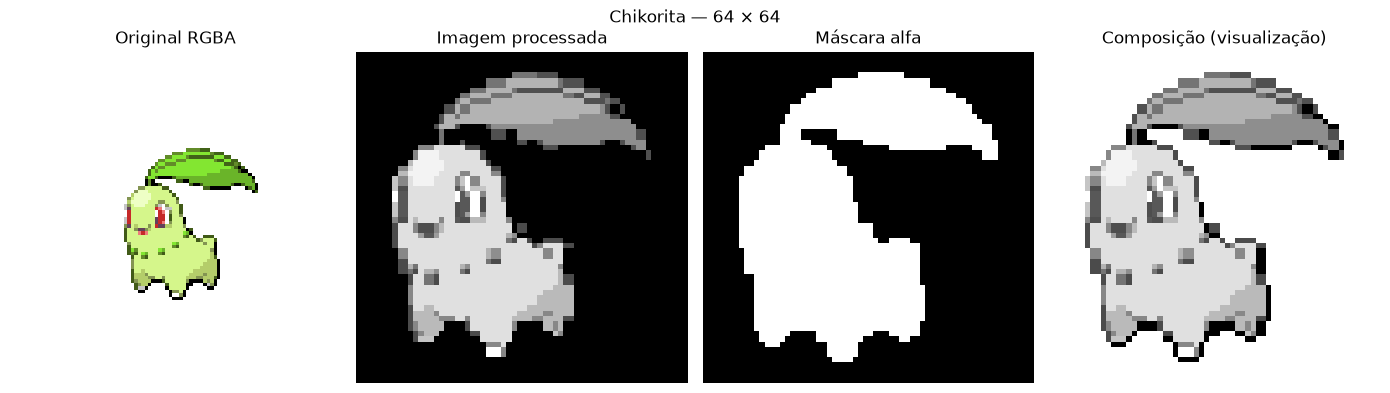

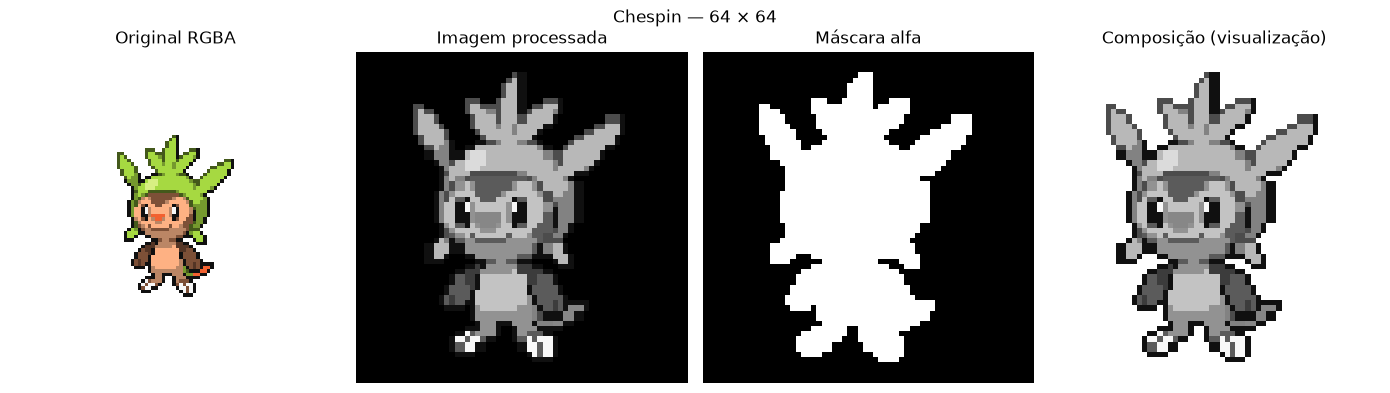

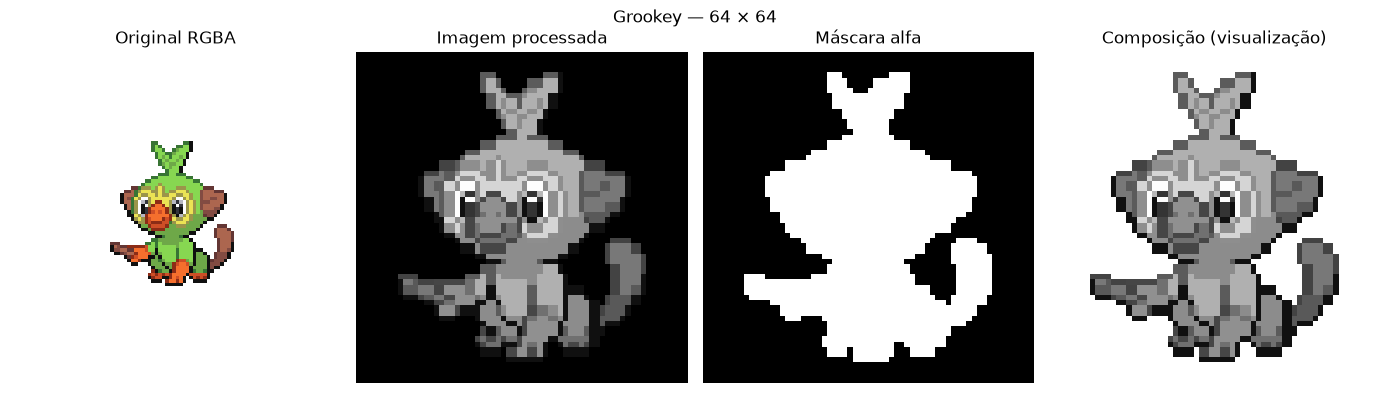

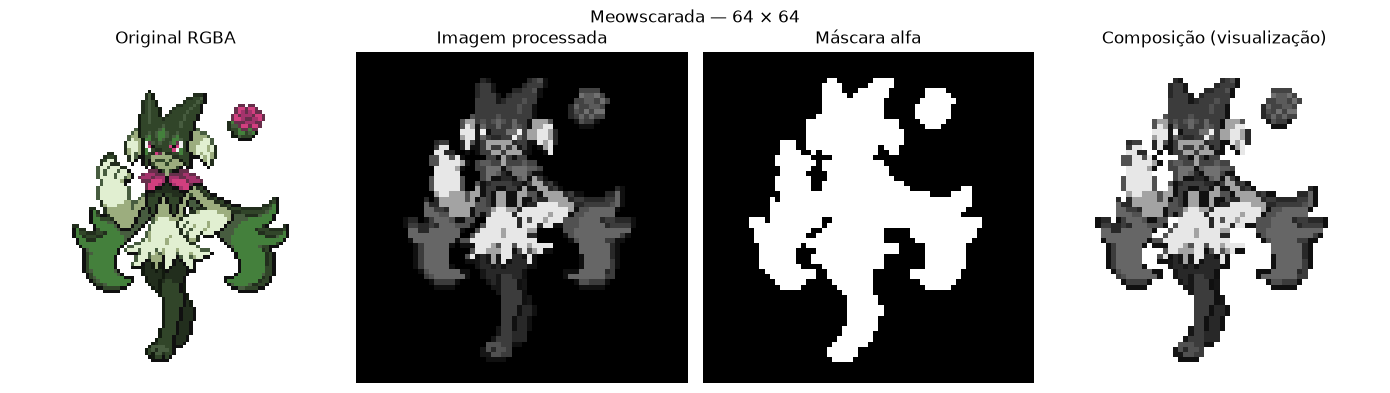

In [58]:
for _, row in sample_df.iterrows():

    visualize_masked_processing(row)

In [59]:
from tqdm.auto import tqdm

records = []

for _, row in tqdm(
    df_split.iterrows(),
    total=len(df_split)
):

    pokemon_id = int(row["id"])
    pokemon_name = row["pokemon_name"]

    raw_path = Path(row["raw_path"])

    filename = f"{pokemon_id:04d}_{pokemon_name}.png"

    image_path = IMAGE_DIR / filename
    mask_path = MASK_DIR / filename

    if not raw_path.exists():

        records.append({
            "id": pokemon_id,
            "image_path": None,
            "mask_path": None,
            "masked_status": "missing_raw"
        })

        continue

    try:

        image, mask = process_sprite_masked(
            raw_path,
            image_size=IMAGE_SIZE,
            margin=MARGIN
        )

        image.save(image_path, format="PNG")
        mask.save(mask_path, format="PNG")

        records.append({
            "id": pokemon_id,
            "image_path": str(image_path),
            "mask_path": str(mask_path),
            "masked_status": "processed"
        })

    except Exception as error:

        records.append({
            "id": pokemon_id,
            "image_path": None,
            "mask_path": None,
            "masked_status": f"error: {error}"
        })

df_processed = pd.DataFrame(records)

df_masked = df_split.drop(
    columns=["image_path", "mask_path", "masked_status"],
    errors="ignore"
).merge(
    df_processed,
    on="id",
    how="left"
)

print("Resultado do processamento:")
display(
    df_masked["masked_status"]
    .value_counts()
    .to_frame("quantidade")
)

  0%|          | 0/1025 [00:00<?, ?it/s]

Resultado do processamento:


,quantidade
masked_status,
processed,1025


In [60]:
def serialize_types(value):

    if isinstance(value, (list, tuple)):
        return "|".join(value)

    return str(value)


df_to_save = df_masked.copy()

df_to_save["types"] = df_to_save["types"].apply(
    serialize_types
)

df_to_save.to_csv(
    BASE_DIR / "dataset_split_masked.csv",
    index=False
)

print("Metadados salvos com sucesso.")

Metadados salvos com sucesso.


In [61]:
image_stats = []

for _, row in tqdm(
    df_masked.iterrows(),
    total=len(df_masked)
):

    if pd.isna(row["image_path"]) or pd.isna(row["mask_path"]):
        continue

    image = np.array(
        Image.open(row["image_path"]).convert("L")
    )

    mask = np.array(
        Image.open(row["mask_path"]).convert("L")
    )

    image_stats.append({

        "id": row["id"],

        "image_shape": image.shape,

        "mask_shape": mask.shape,

        "foreground_pixels": np.sum(mask > 0),

        "background_pixels": np.sum(mask == 0),

        "nonzero_background_pixels": np.sum(
            image[mask == 0] != 0
        ),

        "mask_values": len(np.unique(mask))
    })

df_image_stats = pd.DataFrame(image_stats)

print("Primeiras estatísticas:")
display(df_image_stats.head(10))

print(
    "\nImagens com pixels diferentes de zero fora da máscara:",
    (df_image_stats["nonzero_background_pixels"] > 0).sum()
)

print(
    "\nDimensões incorretas:",
    (
        (df_image_stats["image_shape"] != (64, 64)) |
        (df_image_stats["mask_shape"] != (64, 64))
    ).sum()
)

  0%|          | 0/1025 [00:00<?, ?it/s]

Primeiras estatísticas:


,id,image_shape,mask_shape,foreground_pixels,background_pixels,nonzero_background_pixels,mask_values
0,1,"(64, 64)","(64, 64)",2164,1932,0,2
1,2,"(64, 64)","(64, 64)",1558,2538,0,2
2,3,"(64, 64)","(64, 64)",1990,2106,0,2
3,4,"(64, 64)","(64, 64)",1465,2631,0,2
4,5,"(64, 64)","(64, 64)",1158,2938,0,2
5,6,"(64, 64)","(64, 64)",1761,2335,0,2
6,7,"(64, 64)","(64, 64)",1788,2308,0,2
7,8,"(64, 64)","(64, 64)",1761,2335,0,2
8,9,"(64, 64)","(64, 64)",1885,2211,0,2
9,10,"(64, 64)","(64, 64)",1663,2433,0,2



Imagens com pixels diferentes de zero fora da máscara: 0

Dimensões incorretas: 0


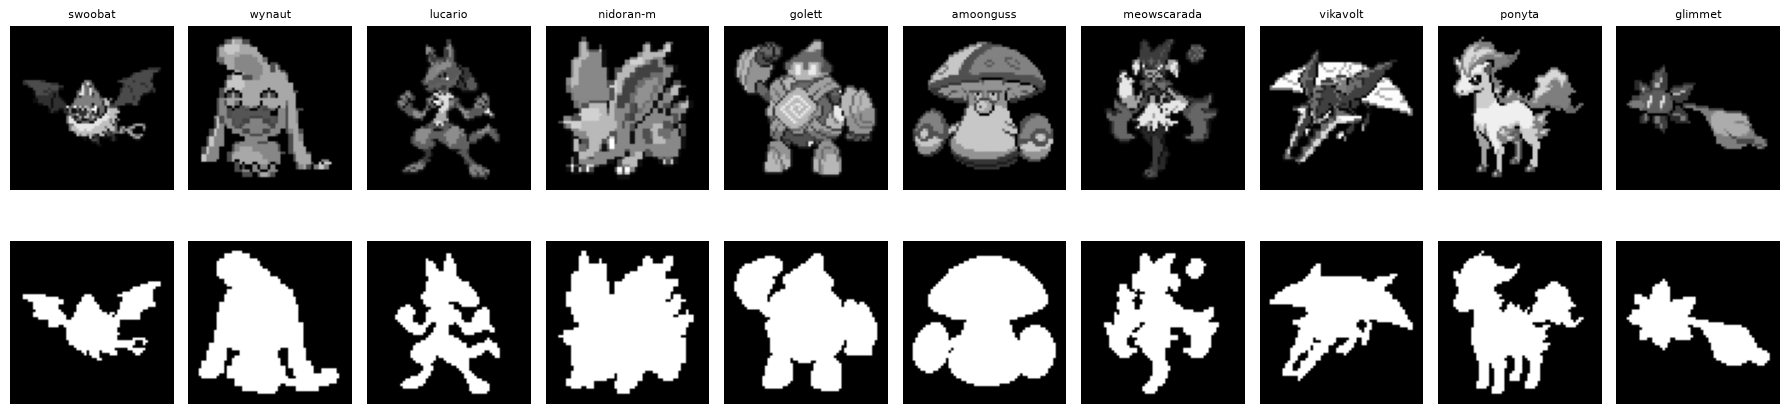

In [62]:
valid_samples = df_masked[
    (df_masked["masked_status"] == "processed")
].sample(
    n=min(10, (df_masked["masked_status"] == "processed").sum()),
    random_state=42
)

fig, axes = plt.subplots(2, 10, figsize=(18, 5))

for i, (_, row) in enumerate(valid_samples.iterrows()):

    image = np.array(
        Image.open(row["image_path"]).convert("L")
    ) / 255.0

    mask = np.array(
        Image.open(row["mask_path"]).convert("L")
    ) / 255.0

    axes[0, i].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(row["pokemon_name"], fontsize=8)

    axes[1, i].imshow(mask, cmap="gray", vmin=0, vmax=1)

    axes[0, i].axis("off")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Imagem")
axes[1, 0].set_ylabel("Máscara")

plt.tight_layout()
plt.show()

Preparação correta dos dataloardes (executar a partir daqui)

In [63]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader

from PIL import Image
from pathlib import Path

BASE_DIR = Path("poke_sprite")

MASKED_CSV = BASE_DIR / "dataset_split_masked.csv"

df_masked = pd.read_csv(MASKED_CSV)

print("Total de Pokémon:", len(df_masked))
print("\nColunas:")
print(df_masked.columns.tolist())

display(
    df_masked[
        ["pokemon_name", "types", "split",
         "image_path", "mask_path"]
    ].head()
)

Total de Pokémon: 1025

Colunas:
['id', 'name', 'pokemon_name', 'generation', 'generation_number', 'types', 'num_types', 'sprite_url', 'raw_path', 'processed_path', 'processing_status', 'split', 'image_path', 'mask_path', 'masked_status']


,pokemon_name,types,split,image_path,mask_path
0,bulbasaur,"['grass', 'poison']",train,poke_sprite\processed_masked\0001_bulbasaur.png,poke_sprite\masks\0001_bulbasaur.png
1,ivysaur,"['grass', 'poison']",train,poke_sprite\processed_masked\0002_ivysaur.png,poke_sprite\masks\0002_ivysaur.png
2,venusaur,"['grass', 'poison']",train,poke_sprite\processed_masked\0003_venusaur.png,poke_sprite\masks\0003_venusaur.png
3,charmander,['fire'],train,poke_sprite\processed_masked\0004_charmander.png,poke_sprite\masks\0004_charmander.png
4,charmeleon,['fire'],train,poke_sprite\processed_masked\0005_charmeleon.png,poke_sprite\masks\0005_charmeleon.png


In [64]:
def parse_types(value):

    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    value = str(value).strip()

    if "|" in value:
        return [
            item.strip()
            for item in value.split("|")
            if item.strip()
        ]

    if value.startswith("[") and value.endswith("]"):

        try:
            return ast.literal_eval(value)

        except (ValueError, SyntaxError):
            value = value[1:-1]

    value = value.replace("'", "").replace('"', "")

    return [
        item.strip()
        for item in value.split(",")
        if item.strip()
    ]


df_masked["types"] = df_masked["types"].apply(parse_types)

display(
    df_masked[
        ["pokemon_name", "types", "split"]
    ].head(10)
)

,pokemon_name,types,split
0,bulbasaur,"[grass, poison]",train
1,ivysaur,"[grass, poison]",train
2,venusaur,"[grass, poison]",train
3,charmander,[fire],train
4,charmeleon,[fire],train
5,charizard,"[fire, flying]",train
6,squirtle,[water],train
7,wartortle,[water],train
8,blastoise,[water],train
9,caterpie,[bug],train


In [65]:
required_columns = [
    "pokemon_name",
    "types",
    "split",
    "image_path",
    "mask_path"
]

missing_columns = [
    col for col in required_columns
    if col not in df_masked.columns
]

assert not missing_columns, (
    f"Colunas ausentes: {missing_columns}"
)

image_exists = df_masked["image_path"].apply(
    lambda path: isinstance(path, str) and Path(path).is_file()
)

mask_exists = df_masked["mask_path"].apply(
    lambda path: isinstance(path, str) and Path(path).is_file()
)

print("Imagens encontradas:", image_exists.sum())
print("Máscaras encontradas:", mask_exists.sum())

print(
    "Registros com arquivos ausentes:",
    (~(image_exists & mask_exists)).sum()
)

Imagens encontradas: 1025
Máscaras encontradas: 1025
Registros com arquivos ausentes: 0


In [66]:
df_masked = df_masked[
    image_exists & mask_exists
].copy().reset_index(drop=True)

print("Registros válidos:", len(df_masked))

Registros válidos: 1025


In [67]:
POKEMON_TYPES = [
    "normal",
    "fire",
    "water",
    "electric",
    "grass",
    "ice",
    "fighting",
    "poison",
    "ground",
    "flying",
    "psychic",
    "bug",
    "rock",
    "ghost",
    "dragon",
    "dark",
    "steel",
    "fairy"
]

TYPE_TO_IDX = {
    pokemon_type: idx
    for idx, pokemon_type in enumerate(POKEMON_TYPES)
}

NUM_TYPES = len(POKEMON_TYPES)

print("Quantidade de condições:", NUM_TYPES)
print(TYPE_TO_IDX)

Quantidade de condições: 18
{'normal': 0, 'fire': 1, 'water': 2, 'electric': 3, 'grass': 4, 'ice': 5, 'fighting': 6, 'poison': 7, 'ground': 8, 'flying': 9, 'psychic': 10, 'bug': 11, 'rock': 12, 'ghost': 13, 'dragon': 14, 'dark': 15, 'steel': 16, 'fairy': 17}


In [68]:
def encode_types(types):

    condition = torch.zeros(
        NUM_TYPES,
        dtype=torch.float32
    )

    for pokemon_type in types:

        if pokemon_type not in TYPE_TO_IDX:
            raise ValueError(
                f"Tipo desconhecido: {pokemon_type}"
            )

        condition[TYPE_TO_IDX[pokemon_type]] = 1.0

    return condition

In [69]:
class PokemonDataset(Dataset):

    def __init__(self, dataframe):

        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        # Carregar imagem em escala de cinza
        image = Image.open(
            row["image_path"]
        ).convert("L")

        image = np.asarray(
            image,
            dtype=np.float32
        ) / 255.0

        # Carregar máscara alfa
        mask = Image.open(
            row["mask_path"]
        ).convert("L")

        mask = np.asarray(
            mask,
            dtype=np.float32
        ) / 255.0

        # Garantir pixels nulos fora da máscara
        image = image * (mask > 0).astype(np.float32)

        # Converter para tensores
        image = torch.from_numpy(
            image.copy()
        ).unsqueeze(0)

        mask = torch.from_numpy(
            mask.copy()
        ).unsqueeze(0)

        # Criar condição
        condition = encode_types(row["types"])

        return image, mask, condition

In [70]:
df_train = df_masked[
    df_masked["split"] == "train"
].copy()

df_val = df_masked[
    df_masked["split"] == "validation"
].copy()

df_test = df_masked[
    df_masked["split"] == "test"
].copy()

print("Treinamento:", len(df_train))
print("Validação:", len(df_val))
print("Teste:", len(df_test))

Treinamento: 905
Validação: 60
Teste: 60


In [71]:
train_dataset = PokemonDataset(df_train)

val_dataset = PokemonDataset(df_val)

test_dataset = PokemonDataset(df_test)

print("\nDatasets criados:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


Datasets criados:
Train: 905
Validation: 60
Test: 60


In [72]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [73]:
images, masks, conditions = next(iter(train_loader))

print("Shape das imagens:", images.shape)
print("Shape das máscaras:", masks.shape)
print("Shape das condições:", conditions.shape)

print("\nTipos dos tensores:")
print("Imagem:", images.dtype)
print("Máscara:", masks.dtype)
print("Condição:", conditions.dtype)

print("\nIntervalos:")
print(
    "Imagem:",
    images.min().item(),
    images.max().item()
)

print(
    "Máscara:",
    masks.min().item(),
    masks.max().item()
)

print(
    "Condição:",
    torch.unique(conditions)
)

Shape das imagens: torch.Size([32, 1, 64, 64])
Shape das máscaras: torch.Size([32, 1, 64, 64])
Shape das condições: torch.Size([32, 18])

Tipos dos tensores:
Imagem: torch.float32
Máscara: torch.float32
Condição: torch.float32

Intervalos:
Imagem: 0.0 1.0
Máscara: 0.0 1.0
Condição: tensor([0., 1.])


In [74]:
assert images.shape == (BATCH_SIZE, 1, 64, 64)

assert masks.shape == (BATCH_SIZE, 1, 64, 64)

assert conditions.shape == (BATCH_SIZE, NUM_TYPES)

assert torch.isfinite(images).all()
assert torch.isfinite(masks).all()
assert torch.isfinite(conditions).all()

assert images.min() >= 0 and images.max() <= 1
assert masks.min() >= 0 and masks.max() <= 1

assert torch.all(
    images[masks == 0] == 0
)

assert torch.all(
    (conditions == 0) | (conditions == 1)
)

print("Todas as verificações passaram!")

Todas as verificações passaram!


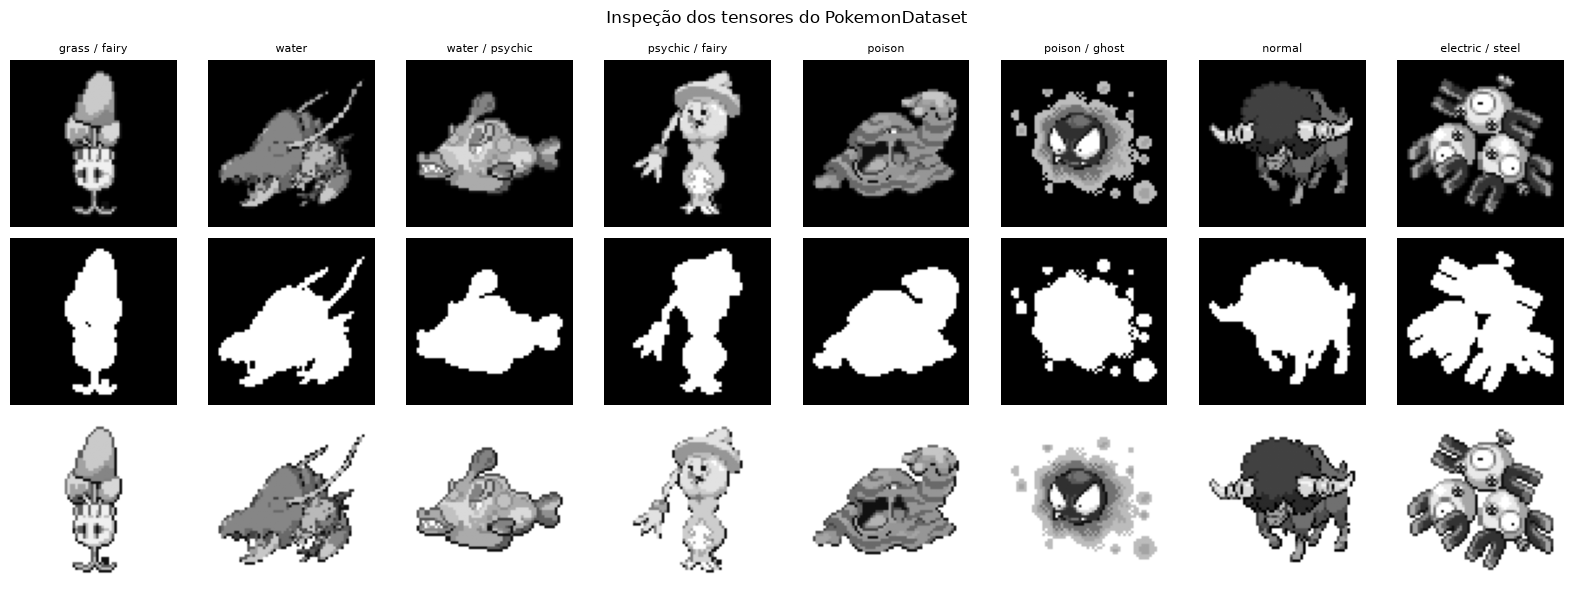

In [75]:
n = 8

fig, axes = plt.subplots(
    3, n,
    figsize=(16, 6)
)

for i in range(n):

    image = images[i, 0].numpy()
    mask = masks[i, 0].numpy()

    # Composição apenas para visualização
    preview = image * mask + (1 - mask)

    types = decode_condition(conditions[i])

    axes[0, i].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[0, i].set_title(
        " / ".join(types),
        fontsize=8
    )

    axes[1, i].imshow(
        mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[2, i].imshow(
        preview,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    for j in range(3):
        axes[j, i].axis("off")

axes[0, 0].set_ylabel("Imagem")
axes[1, 0].set_ylabel("Máscara")
axes[2, 0].set_ylabel("Preview")

plt.suptitle("Inspeção dos tensores do PokemonDataset")
plt.tight_layout()
plt.show()

In [76]:
def analyze_dataset_occupancy(loader):

    occupancies = []
    active_types = []

    for images, masks, conditions in loader:

        occupancy = masks.mean(
            dim=(1, 2, 3)
        )

        n_types = conditions.sum(dim=1)

        occupancies.extend(
            occupancy.numpy()
        )

        active_types.extend(
            n_types.numpy()
        )

    occupancies = np.array(occupancies)
    active_types = np.array(active_types)

    print(f"Quantidade de amostras: {len(occupancies)}")
    print(f"Ocupação média: {occupancies.mean()*100:.2f}%")
    print(f"Ocupação mínima: {occupancies.min()*100:.2f}%")
    print(f"Ocupação máxima: {occupancies.max()*100:.2f}%")

    print("\nQuantidade de tipos por Pokémon:")
    print(pd.Series(active_types).value_counts().sort_index())

    return occupancies

In [77]:
train_occupancy = analyze_dataset_occupancy(train_loader)

print("\nValidação:")
val_occupancy = analyze_dataset_occupancy(val_loader)

print("\nTeste:")
test_occupancy = analyze_dataset_occupancy(test_loader)

Quantidade de amostras: 905
Ocupação média: 34.40%
Ocupação mínima: 14.62%
Ocupação máxima: 58.50%

Quantidade de tipos por Pokémon:
1.0    456
2.0    449
Name: count, dtype: int64

Validação:
Quantidade de amostras: 60
Ocupação média: 33.24%
Ocupação mínima: 17.97%
Ocupação máxima: 50.59%

Quantidade de tipos por Pokémon:
1.0    22
2.0    38
Name: count, dtype: int64

Teste:
Quantidade de amostras: 60
Ocupação média: 32.44%
Ocupação mínima: 12.87%
Ocupação máxima: 53.59%

Quantidade de tipos por Pokémon:
1.0    21
2.0    39
Name: count, dtype: int64


In [78]:
latest_generation = int(
    df_masked["generation_number"].max()
)

print("Última geração:", latest_generation)

display(
    df_masked.groupby(
        ["split", "generation_number"]
    ).size().to_frame("Quantidade")
)

Última geração: 9


Quantidade
split      generation_number            
test       9                          60
train      1                         151
           2                         100
           3                         135
           4                         107
           5                         156
           6                          72
           7                          88
           8                          96
validation 9                          60

In [79]:
assert (
    df_train["generation_number"] < latest_generation
).all()

assert (
    df_val["generation_number"] == latest_generation
).all()

assert (
    df_test["generation_number"] == latest_generation
).all()

assert set(df_train["id"]).isdisjoint(set(df_val["id"]))

assert set(df_train["id"]).isdisjoint(set(df_test["id"]))

assert set(df_val["id"]).isdisjoint(set(df_test["id"]))

print("Divisão dos dados validada!")

Divisão dos dados validada!


# Modelo

In [113]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Encoder(nn.Module):

    def __init__(self, latent_dim=64, num_types=18):
        super().__init__()

        self.conv = nn.Sequential(

            # 19 x 64 x 64 -> 32 x 32 x 32
            nn.Conv2d(
                1 + num_types,
                32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            # 32 x 32 x 32 -> 64 x 16 x 16
            nn.Conv2d(
                32, 64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            # 64 x 16 x 16 -> 128 x 8 x 8
            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            # 128 x 8 x 8 -> 128 x 4 x 4
            nn.Conv2d(
                128, 128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Flatten()
        )

        self.fc = nn.Sequential(
            nn.Linear(128 * 4 * 4, 512),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(512, latent_dim)

        self.fc_logvar = nn.Linear(512, latent_dim)

    def forward(self, x, c):

        # Transformar os tipos em mapas espaciais
        c_map = c.unsqueeze(2).unsqueeze(3)

        c_map = c_map.expand(
            -1,
            -1,
            x.size(2),
            x.size(3)
        )

        # Entrada: imagem + condição
        encoder_input = torch.cat(
            [x, c_map],
            dim=1
        )

        h = self.conv(encoder_input)

        h = self.fc(h)

        mu = self.fc_mu(h)

        logvar = self.fc_logvar(h)

        return mu, logvar

In [114]:
def reparameterize(mu, logvar):

    std = torch.exp(0.5 * logvar)

    epsilon = torch.randn_like(std)

    z = mu + std * epsilon

    return z

In [115]:
class Decoder(nn.Module):

    def __init__(self, latent_dim=64, num_types=18):
        super().__init__()

        self.fc = nn.Sequential(

            nn.Linear(
                latent_dim + num_types,
                512
            ),
            nn.ReLU(),

            nn.Linear(
                512,
                128 * 4 * 4
            ),
            nn.ReLU()
        )

        self.deconv = nn.Sequential(

            nn.Unflatten(
                1,
                (128, 4, 4)
            ),

            # 128 x 4 x 4 -> 128 x 8 x 8
            nn.ConvTranspose2d(
                128, 128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            # 128 x 8 x 8 -> 64 x 16 x 16
            nn.ConvTranspose2d(
                128, 64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            # 64 x 16 x 16 -> 32 x 32 x 32
            nn.ConvTranspose2d(
                64, 32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            # 32 x 32 x 32 -> 1 x 64 x 64
            nn.ConvTranspose2d(
                32, 1,
                kernel_size=4,
                stride=2,
                padding=1
            ),

            nn.Sigmoid()
        )

    def forward(self, z, c):

        # Concatenar vetor latente e tipos
        z = torch.cat([z, c], dim=1)

        h = self.fc(z)

        reconstruction = self.deconv(h)

        return reconstruction

In [116]:
class CVAE(nn.Module):

    def __init__(self, latent_dim=64, num_types=18):
        super().__init__()

        self.encoder = Encoder(
            latent_dim=latent_dim,
            num_types=num_types
        )

        self.decoder = Decoder(
            latent_dim=latent_dim,
            num_types=num_types
        )

    def forward(self, x, c):

        mu, logvar = self.encoder(x, c)

        z = reparameterize(mu, logvar)

        reconstruction = self.decoder(z, c)

        return reconstruction, mu, logvar

In [117]:
def masked_reconstruction_loss(x, reconstruction, mask):

    # Erro absoluto entre imagem real e reconstruída
    pixel_error = torch.abs(
        x - reconstruction
    )

    # Desconsiderar pixels transparentes
    masked_error = pixel_error * mask

    # Soma por imagem e média entre imagens
    loss_per_sample = masked_error.sum(
        dim=(1, 2, 3)
    )

    return loss_per_sample.mean()

In [118]:
def kl_divergence(mu, logvar):

    kl_per_sample = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp(),
        dim=1
    )

    return kl_per_sample.mean()

In [119]:
def cvae_loss(
    x,
    mask,
    reconstruction,
    mu,
    logvar,
    beta=1.0
):

    recon_loss = masked_reconstruction_loss(
        x,
        reconstruction,
        mask
    )

    kl_loss = kl_divergence(
        mu,
        logvar
    )

    total_loss = recon_loss + beta * kl_loss

    return total_loss, recon_loss, kl_loss

In [120]:
LATENT_DIM = 64
NUM_TYPES = 18

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = CVAE(
    latent_dim=LATENT_DIM,
    num_types=NUM_TYPES
).to(device)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("Dispositivo:", device)
print(f"Parâmetros treináveis: {total_params:,}")

Dispositivo: cuda
Parâmetros treináveis: 3,070,657


In [121]:
images, masks, conditions = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)
conditions = conditions.to(device)

model.eval()

with torch.no_grad():

    reconstruction, mu, logvar = model(
        images,
        conditions
    )

    loss, recon_loss, kl_loss = cvae_loss(
        images,
        masks,
        reconstruction,
        mu,
        logvar,
        beta=1.0
    )

print("Imagem:", images.shape)
print("Máscara:", masks.shape)
print("Condição:", conditions.shape)

print("\nReconstrução:", reconstruction.shape)
print("Mu:", mu.shape)
print("Logvar:", logvar.shape)

print("\nLoss total:", loss.item())
print("Reconstrução:", recon_loss.item())
print("KL:", kl_loss.item())

Imagem: torch.Size([32, 1, 64, 64])
Máscara: torch.Size([32, 1, 64, 64])
Condição: torch.Size([32, 18])

Reconstrução: torch.Size([32, 1, 64, 64])
Mu: torch.Size([32, 64])
Logvar: torch.Size([32, 64])

Loss total: 343.1001281738281
Reconstrução: 343.0641174316406
KL: 0.03600125387310982


# Treinamento

In [122]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    device,
    beta
):

    model.train()

    total_loss = 0
    total_recon = 0
    total_kl = 0

    for images, masks, conditions in loader:

        images = images.to(device)
        masks = masks.to(device)
        conditions = conditions.to(device)

        optimizer.zero_grad()

        # O modelo recebe somente imagem e condição
        reconstruction, mu, logvar = model(
            images,
            conditions
        )

        # A máscara aparece somente na loss
        loss, recon_loss, kl_loss = cvae_loss(
            images,
            masks,
            reconstruction,
            mu,
            logvar,
            beta=beta
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

    n = len(loader.dataset)

    return {
        "total": total_loss / n,
        "recon": total_recon / n,
        "kl": total_kl / n
    }

In [123]:
def validate_one_epoch(
    model,
    loader,
    device,
    beta
):

    model.eval()

    total_loss = 0
    total_recon = 0
    total_kl = 0

    with torch.no_grad():

        for images, masks, conditions in loader:

            images = images.to(device)
            masks = masks.to(device)
            conditions = conditions.to(device)

            # Encoder sem máscara
            mu, logvar = model.encoder(
                images,
                conditions
            )

            # Decoder sem máscara
            reconstruction = model.decoder(
                mu,
                conditions
            )

            # Máscara utilizada somente para avaliar a reconstrução
            loss, recon_loss, kl_loss = cvae_loss(
                images,
                masks,
                reconstruction,
                mu,
                logvar,
                beta=beta
            )

            total_loss += loss.item()
            total_recon += recon_loss.item()
            total_kl += kl_loss.item()

    n = len(loader.dataset)

    return {
        "total": total_loss / n,
        "recon": total_recon / n,
        "kl": total_kl / n
    }

In [124]:
EPOCHS = 150

LEARNING_RATE = 1e-3

BETA_MAX = 1.0

WARMUP_EPOCHS = 40

PATIENCE = 20

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=7,
    min_lr=1e-6
)

best_val_loss = float("inf")
epochs_without_improvement = 0

checkpoint_path = BASE_DIR / "cvae_image_only_best.pt"

history = {
    "beta": [],
    "train_total": [],
    "train_recon": [],
    "train_kl": [],
    "val_total": [],
    "val_recon": [],
    "val_kl": []
}

In [125]:
for epoch in range(EPOCHS):

    beta = min(
        BETA_MAX,
        (epoch + 1) / WARMUP_EPOCHS
    )

    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        device,
        beta
    )

    val_metrics = validate_one_epoch(
        model,
        val_loader,
        device,
        beta
    )

    history["beta"].append(beta)

    for metric in ["total", "recon", "kl"]:

        history[f"train_{metric}"].append(
            train_metrics[metric]
        )

        history[f"val_{metric}"].append(
            val_metrics[metric]
        )

    if beta >= BETA_MAX:

        scheduler.step(val_metrics["total"])

        if val_metrics["total"] < best_val_loss:

            best_val_loss = val_metrics["total"]

            epochs_without_improvement = 0

            torch.save(
                {
                    "epoch": epoch + 1,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "best_val_loss": best_val_loss,
                    "latent_dim": LATENT_DIM,
                    "num_types": NUM_TYPES
                },
                checkpoint_path
            )

        else:

            epochs_without_improvement += 1

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Beta: {beta:.3f} | "
        f"Train: {train_metrics['total']:.4f} | "
        f"Recon: {train_metrics['recon']:.4f} | "
        f"KL: {train_metrics['kl']:.4f} | "
        f"Val: {val_metrics['total']:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if (
        beta >= BETA_MAX
        and epochs_without_improvement >= PATIENCE
    ):

        print(f"\nEarly stopping na época {epoch+1}.")
        break

print("\nMelhor loss de validação:", best_val_loss)

Epoch [1/150] Beta: 0.025 | Train: 10.5131 | Recon: 10.5130 | KL: 0.0064 | Val: 10.2227 | LR: 0.001000
Epoch [2/150] Beta: 0.050 | Train: 10.3608 | Recon: 10.3556 | KL: 0.1038 | Val: 10.1694 | LR: 0.001000
Epoch [3/150] Beta: 0.075 | Train: 10.1026 | Recon: 10.0798 | KL: 0.3046 | Val: 9.7670 | LR: 0.001000
Epoch [4/150] Beta: 0.100 | Train: 9.8117 | Recon: 9.7702 | KL: 0.4150 | Val: 9.4494 | LR: 0.001000
Epoch [5/150] Beta: 0.125 | Train: 9.7038 | Recon: 9.6579 | KL: 0.3668 | Val: 9.6485 | LR: 0.001000
Epoch [6/150] Beta: 0.150 | Train: 9.5351 | Recon: 9.4815 | KL: 0.3573 | Val: 9.3615 | LR: 0.001000
Epoch [7/150] Beta: 0.175 | Train: 9.4339 | Recon: 9.3512 | KL: 0.4728 | Val: 9.2079 | LR: 0.001000
Epoch [8/150] Beta: 0.200 | Train: 9.3224 | Recon: 9.2402 | KL: 0.4112 | Val: 9.3858 | LR: 0.001000
Epoch [9/150] Beta: 0.225 | Train: 9.3034 | Recon: 9.2066 | KL: 0.4303 | Val: 9.1823 | LR: 0.001000
Epoch [10/150] Beta: 0.250 | Train: 9.3037 | Recon: 9.2000 | KL: 0.4151 | Val: 9.0826 | LR: 

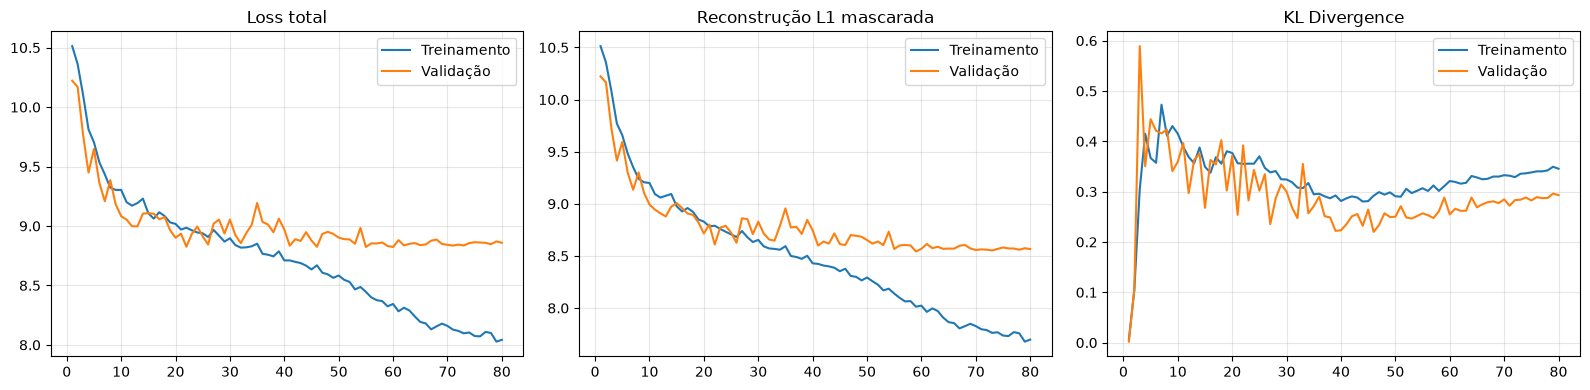

In [126]:
epochs = range(1, len(history["train_total"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Loss total
axes[0].plot(
    epochs,
    history["train_total"],
    label="Treinamento"
)

axes[0].plot(
    epochs,
    history["val_total"],
    label="Validação"
)

axes[0].set_title("Loss total")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Reconstruction
axes[1].plot(
    epochs,
    history["train_recon"],
    label="Treinamento"
)

axes[1].plot(
    epochs,
    history["val_recon"],
    label="Validação"
)

axes[1].set_title("Reconstrução L1 mascarada")
axes[1].legend()
axes[1].grid(alpha=0.3)

# KL
axes[2].plot(
    epochs,
    history["train_kl"],
    label="Treinamento"
)

axes[2].plot(
    epochs,
    history["val_kl"],
    label="Validação"
)

axes[2].set_title("KL Divergence")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [127]:
def visualize_reconstructions(
    model,
    loader,
    device,
    n=8
):

    model.eval()

    images, masks, conditions = next(iter(loader))

    images = images[:n].to(device)
    masks = masks[:n].to(device)
    conditions = conditions[:n].to(device)

    with torch.no_grad():

        mu, logvar = model.encoder(
            images,
            conditions
        )

        reconstruction = model.decoder(
            mu,
            conditions
        )

        # Apenas para visualizar a região válida
        masked_preview = reconstruction * masks

    fig, axes = plt.subplots(
        4, n,
        figsize=(2*n, 9)
    )

    for i in range(n):

        visuals = [
            images[i, 0],
            masks[i, 0],
            reconstruction[i, 0],
            masked_preview[i, 0]
        ]

        titles = [
            "Original",
            "Máscara (referência)",
            "Reconstrução bruta",
            "Reconstrução mascarada"
        ]

        for j in range(4):

            axes[j, i].imshow(
                visuals[j].cpu(),
                cmap="gray",
                vmin=0,
                vmax=1
            )

            axes[j, i].set_title(
                titles[j],
                fontsize=8
            )

            axes[j, i].axis("off")

    plt.tight_layout()
    plt.show()

In [128]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Melhor época:", checkpoint["epoch"])
print("Melhor validação:", checkpoint["best_val_loss"])

Melhor época: 60
Melhor validação: 8.823408762613932


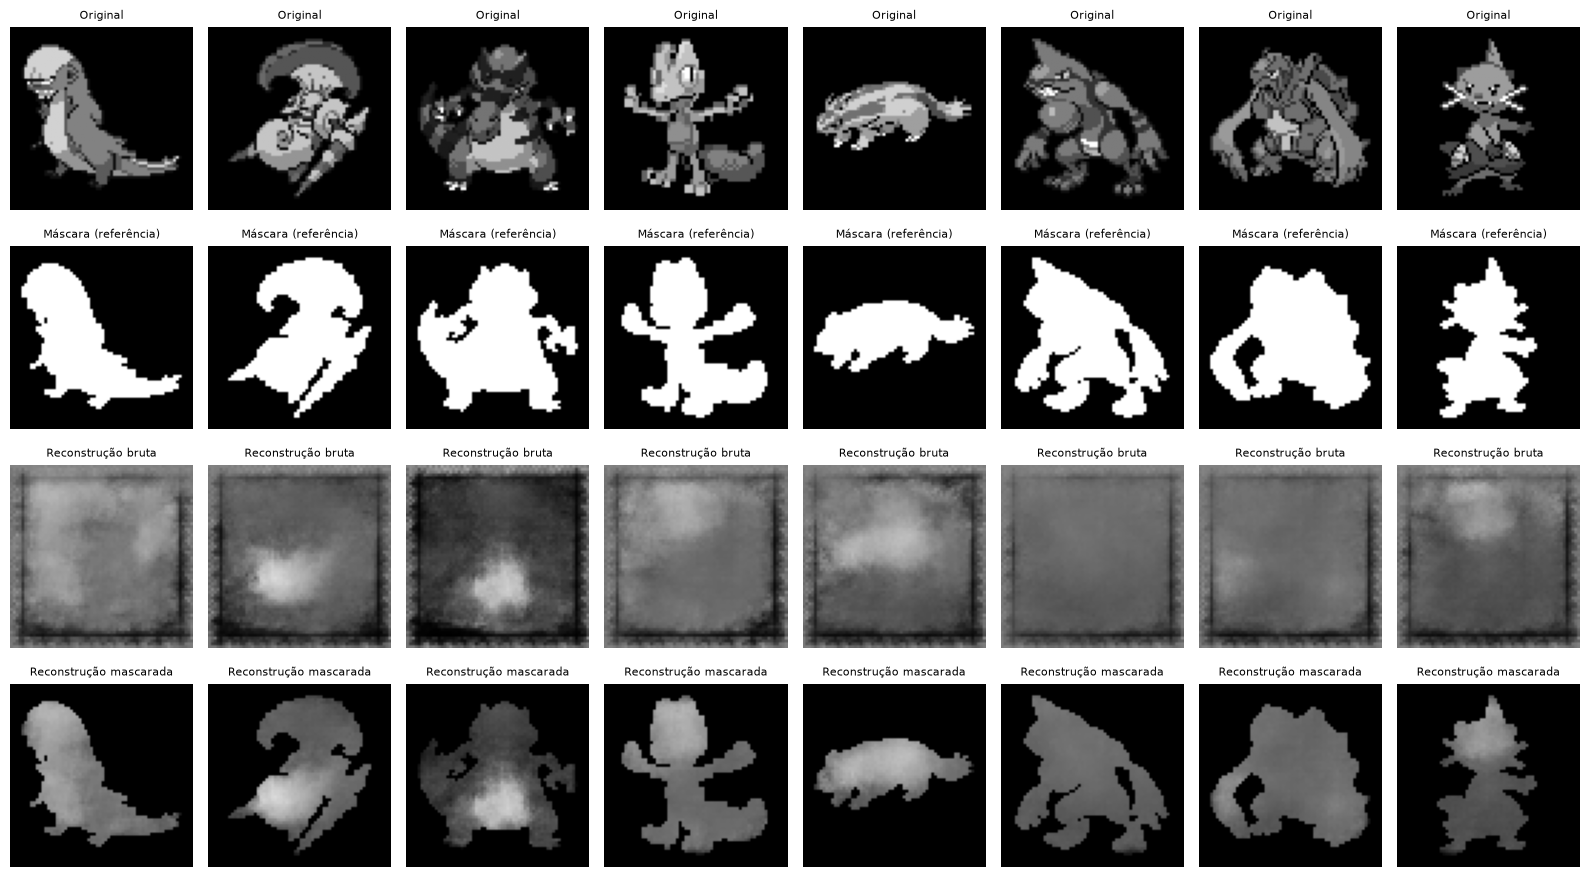

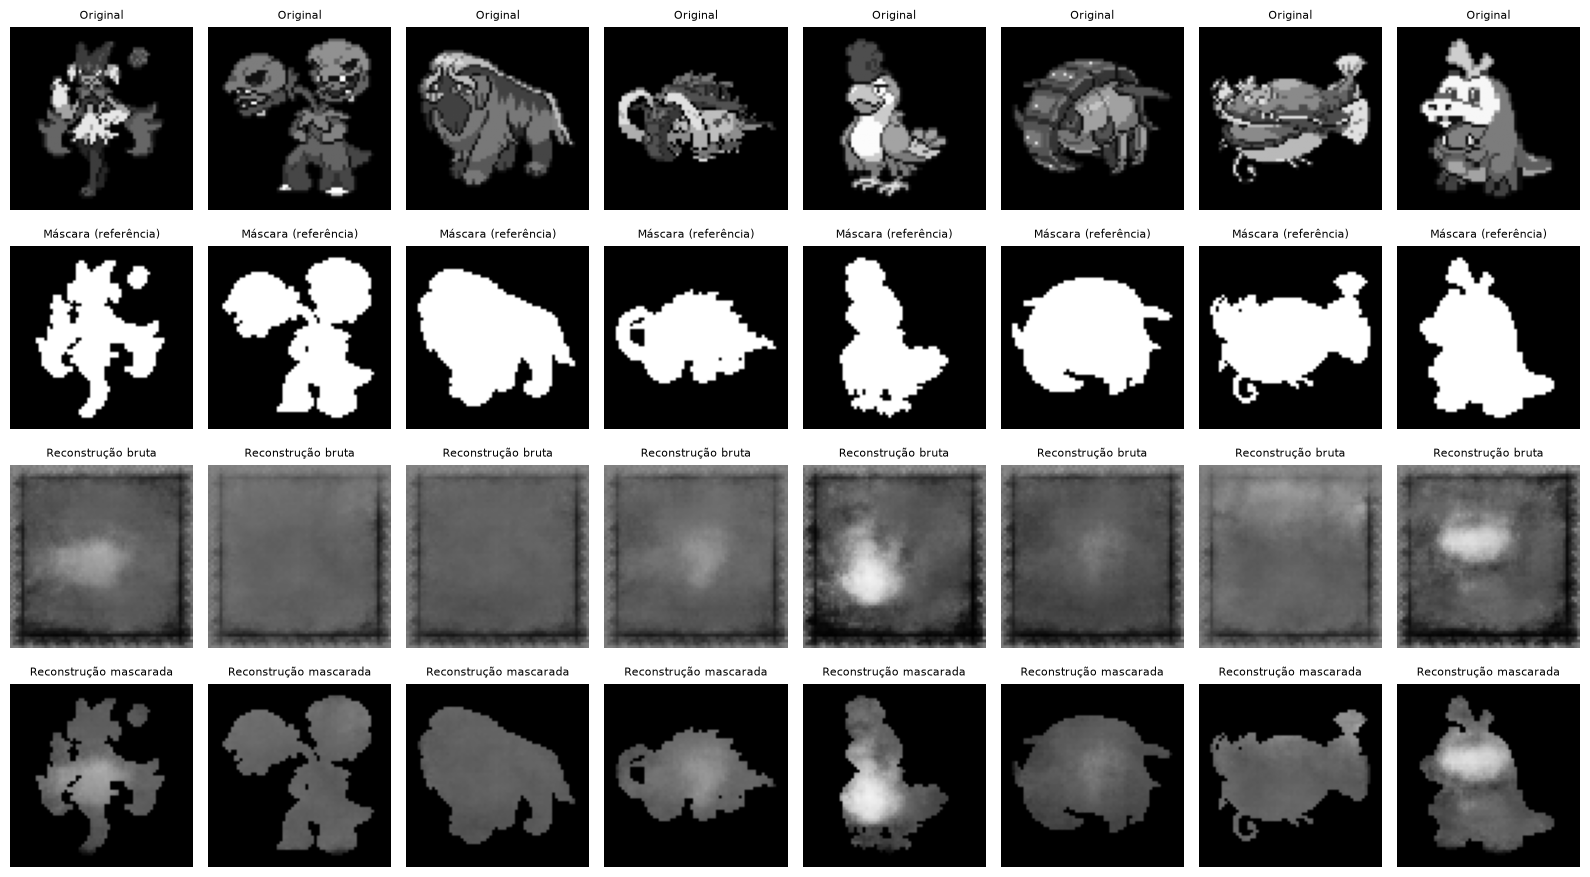

In [129]:
visualize_reconstructions(
    model,
    train_loader,
    device
)

visualize_reconstructions(
    model,
    val_loader,
    device
)